https://catalogo.datos.gba.gob.ar/da_DK/dataset/unidades-de-servicio-y-matricula/archivo/2b20bb14-e8c0-4066-a8d7-dc9db02300df

In [69]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [70]:
ruta = "../data/raw/evolucion-unidades-servicio-y-matricula-region-educativa-2015_2025.xlsx"

df_regional = pd.read_excel(ruta)

In [71]:
df_regional.shape


(275, 5)

In [72]:
df_regional.columns.tolist()

['anio', 'region', 'unidades_de_servicio', 'matricula', 'docentes']

In [73]:
df_regional.head()

,anio,region,unidades_de_servicio,matricula,docentes
0,2015,1,1299,308422,29018
1,2015,2,1649,433822,44135
2,2015,3,1311,407180,36492
3,2015,4,1405,413158,39152
4,2015,5,1147,355711,31696


1. ¿Qué años tiene?


In [74]:
print(df_regional["anio"].unique())

[2015 2016 2017 2018 2019 2020 2021 2022 2023 2024 2025]


2.¿Qué regiones tenemos?

In [75]:
print(df_regional["region"].unique())

[ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24
 25]


In [76]:
# anio + region es la clave del dataset
df_regional.duplicated(
    subset=["anio", "region"]
).sum()

np.int64(0)

3. Tipos de datos

In [77]:
df_regional.dtypes

anio                    int64
region                  int64
unidades_de_servicio    int64
matricula               int64
docentes                int64
dtype: object

4. Valores faltantes

In [78]:
df_regional.isna().sum()

anio                    0
region                  0
unidades_de_servicio    0
matricula               0
docentes                0
dtype: int64

In [79]:
df_regional.describe()

,anio,region,unidades_de_servicio,matricula,docentes
count,275.000000,275.00000,275.000000,275.000000,275.000000
mean,2020.000000,13.00000,865.290909,203222.476364,21796.912727
std,3.168043,7.22425,352.990120,142185.523926,13786.254409
min,2015.000000,1.00000,385.000000,41415.000000,4607.000000
25%,2017.000000,7.00000,565.500000,84081.500000,9644.500000
50%,2020.000000,13.00000,742.000000,148466.000000,16759.000000
75%,2023.000000,19.00000,1166.500000,319837.000000,33729.000000
max,2025.000000,25.00000,1649.000000,463532.000000,56450.000000


In [80]:
df_regional.groupby("anio")[
    ["unidades_de_servicio", "matricula", "docentes"]
].sum()

,unidades_de_servicio,matricula,docentes
anio,,,
2015,22137,4914177,491441
2016,22266,4973391,511186
2017,21825,5044150,512279
2018,21700,5109878,521338
2019,21620,5218472,534777
2020,21219,5138086,548445
2021,21256,5159560,552001
2022,21388,5149536,567009
2023,21522,5124691,580012


Quiero calcular el cambio porcentual 2015 → 2025 de las tres variables

In [81]:
totales_anuales = (
    df_regional
    .groupby("anio")[
        ["unidades_de_servicio", "matricula", "docentes"]
    ]
    .sum()
)

totales_anuales

,unidades_de_servicio,matricula,docentes
anio,,,
2015,22137,4914177,491441
2016,22266,4973391,511186
2017,21825,5044150,512279
2018,21700,5109878,521338
2019,21620,5218472,534777
2020,21219,5138086,548445
2021,21256,5159560,552001
2022,21388,5149536,567009
2023,21522,5124691,580012


In [82]:
cambio_2015_2025 = (
    ((totales_anuales.loc[2025] - totales_anuales.loc[2015]) / totales_anuales.loc[2015]) * 100
)

cambio_2015_2025

unidades_de_servicio    -2.791706
matricula                1.776818
docentes                20.228267
dtype: float64

Relación entre matrícula y docentes

In [83]:
totales_anuales["matricula_por_docente"] = (
    totales_anuales["matricula"]
    / totales_anuales["docentes"]
)

totales_anuales

,unidades_de_servicio,matricula,docentes,matricula_por_docente
anio,,,,
2015,22137,4914177,491441,9.999526
2016,22266,4973391,511186,9.729122
2017,21825,5044150,512279,9.846490
2018,21700,5109878,521338,9.801469
2019,21620,5218472,534777,9.758221
2020,21219,5138086,548445,9.368462
2021,21256,5159560,552001,9.347012
2022,21388,5149536,567009,9.081930
2023,21522,5124691,580012,8.835491


In [84]:
totales_anuales["matricula_por_unidad"] = (
    totales_anuales["matricula"]
    / totales_anuales["unidades_de_servicio"]
)

totales_anuales

,unidades_de_servicio,matricula,docentes,matricula_por_docente,matricula_por_unidad
anio,,,,,
2015,22137,4914177,491441,9.999526,221.989294
2016,22266,4973391,511186,9.729122,223.362571
2017,21825,5044150,512279,9.846490,231.117984
2018,21700,5109878,521338,9.801469,235.478249
2019,21620,5218472,534777,9.758221,241.372433
2020,21219,5138086,548445,9.368462,242.145530
2021,21256,5159560,552001,9.347012,242.734287
2022,21388,5149536,567009,9.081930,240.767533
2023,21522,5124691,580012,8.835491,238.114069


### ¿La evolución de la Provincia fue similar en todas las regiones educativas o hubo trayectorias divergentes?
No alcanza con comparar valores absolutos: una región grande puede tener más matrícula que otra y, aun así, crecer proporcionalmente menos. Por eso voy a calcular la variación porcentual de cada región entre 2015 y 2025.
Concepto que vas a aprender
El pivot() me permite reorganizar los datos para comparar dos años por región. Luego calcularemos:
$$
\text{Variación \%} =
\frac{\text{Valor}_{2025} - \text{Valor}_{2015}}
{\text{Valor}_{2015}} \times 100
$$

In [85]:
extremos = df_regional[df_regional["anio"].isin([2015, 2025])]

comparacion = extremos.pivot(
    index="region",
    columns="anio",
    values=["unidades_de_servicio", "matricula", "docentes"]
)

comparacion.columns = [
    f"{variable}_{anio}" for variable, anio in comparacion.columns
]

# Ahora las columnas se llaman "matricula_2015", "matricula_2025", etc.
for variable in ["unidades_de_servicio", "matricula", "docentes"]:
    comparacion[f"{variable}_variacion_pct"] = (
        (comparacion[f"{variable}_2025"] - comparacion[f"{variable}_2015"])
        / comparacion[f"{variable}_2015"]
    ) * 100

variaciones = comparacion[
    [
        "unidades_de_servicio_variacion_pct",
        "matricula_variacion_pct",
        "docentes_variacion_pct",
    ]
].round(2)

#variaciones = variaciones.sort_values("matricula_variacion_pct")
display(comparacion.round(2))

,unidades_de_servicio_2015,unidades_de_servicio_2025,matricula_2015,matricula_2025,docentes_2015,docentes_2025,unidades_de_servicio_variacion_pct,matricula_variacion_pct,docentes_variacion_pct
region,,,,,,,,,
1,1299,1319,308422,328329,29018,41235,1.54,6.45,42.10
2,1649,1574,433822,430479,44135,56450,-4.55,-0.77,27.90
3,1311,1313,407180,428093,36492,45786,0.15,5.14,25.47
4,1405,1303,413158,414946,39152,41035,-7.26,0.43,4.81
5,1147,1189,355711,393126,31696,36527,3.66,10.52,15.24
6,1402,1297,320524,292448,36436,39484,-7.49,-8.76,8.37
7,960,943,231709,218251,24379,28383,-1.77,-5.81,16.42
8,1087,1032,309349,289896,31670,32056,-5.06,-6.29,1.22
9,1361,1335,424794,447540,38822,42491,-1.91,5.35,9.45


Principales resultados

1. La evolución de la matrícula presenta diferencias territoriales importantes.

De las 25 regiones educativas, 13 registraron una disminución de matrícula entre 2015 y 2025, mientras que 12 mostraron un aumento.

Entre las disminuciones más pronunciadas se encuentran:

Región 6: −8,76 %.

Región 8: −6,29 %.

Región 25: −6,04 %.

Región 7: −5,81 %.

En el extremo opuesto, las mayores variaciones positivas corresponden a:

Región 10: +16,98 %.

Región 11: +12,02 %.

Región 5: +10,52 %.

Región 17: +9,61 %.

Estos resultados muestran que la evolución provincial agregada no describe por completo las trayectorias regionales: existen regiones con disminuciones y otras con aumentos de matrícula durante el período.

2. Las unidades de servicio disminuyeron en la mayoría de las regiones.

En 20 de las 25 regiones se observa una variación negativa de las unidades de servicio. Las mayores disminuciones porcentuales corresponden a la Región 6 (−7,49 %), la Región 22 (−7,32 %), la Región 4 (−7,26 %) y la Región 15 (−6,88 %).

Cinco regiones registraron variaciones positivas: las regiones 1, 3, 5, 11 y 17. La Región 24 prácticamente no cambió, con una variación de −0,19 %.

La disminución de unidades de servicio en numerosas regiones coincide con la reducción de matrícula en varias de ellas, pero esa correspondencia no es universal. Por ejemplo, la Región 10 presenta un aumento de matrícula del 16,98 % junto con un aumento de unidades de servicio del 2,44 %. En cambio, la Región 4 registra una variación de matrícula de +0,43 % y una disminución de unidades de servicio del 7,26 %.

3. Los cargos docentes aumentaron en todas las regiones.

Las 25 regiones muestran variaciones positivas en los cargos docentes entre 2015 y 2025. Entre los mayores aumentos porcentuales se encuentran la Región 23 (+82,23 %), la Región 17 (+53,98 %), la Región 1 (+42,10 %) y la Región 18 (+37,29 %).

La Región 23 presenta un valor especialmente elevado respecto del resto. Antes de interpretarlo como una transformación sustantiva del sistema educativo, conviene examinar sus valores absolutos de 2015 y 2025, así como verificar si hubo cambios de registro, cobertura o definición de la variable.

El aumento generalizado de cargos docentes, en paralelo con trayectorias diversas de matrícula, constituye un patrón descriptivo relevante. Sin embargo, los cargos no equivalen a personas: una persona puede ocupar más de un cargo y los valores de esta variable pueden ser decimales. Por eso, los resultados no deben interpretarse directamente como cambios en la cantidad de docentes individuales.

Síntesis interpretativa

La comparación entre 2015 y 2025 permite identificar tres patrones:

- Divergencia territorial de la matrícula: las regiones no evolucionaron de manera uniforme; algunas perdieron matrícula y otras la incrementaron.

- Disminución extendida de unidades de servicio: la mayoría de las regiones registró una reducción porcentual, aunque existen excepciones.

- Aumento de cargos docentes: todas las regiones presentan valores superiores en 2025 respecto de 2015, con diferencias importantes en la magnitud del cambio.



In [86]:
# Filtrar la Región 23 y ordenar por año
region_23 = df_regional.loc[
    df_regional["region"] == 23
].sort_values("anio")

# Examinar la evolución anual de los cargos
region_23[["anio", "docentes"]]

,anio,docentes
22,2015,6972
47,2016,7049
72,2017,7285
97,2018,7687
122,2019,8100
147,2020,7876
172,2021,7966
197,2022,7827
222,2023,8141
247,2024,8793


In [87]:
cargos_2015 = region_23.loc[
    region_23["anio"] == 2015, "docentes"
].iloc[0]

cargos_2025 = region_23.loc[
    region_23["anio"] == 2025, "docentes"
].iloc[0]

diferencia = cargos_2025 - cargos_2015
variacion_porcentual = (diferencia / cargos_2015) * 100

print(f"Cargos en 2015: {cargos_2015}")
print(f"Cargos en 2025: {cargos_2025}")
print(f"Diferencia absoluta: {diferencia}")
print(f"Variación porcentual: {variacion_porcentual:.2f}%")

Cargos en 2015: 6972
Cargos en 2025: 12705
Diferencia absoluta: 5733
Variación porcentual: 82.23%


Entre 2015 y 2024, los cargos pasaron de 6.972 a 8.793. En 2025 llegaron a 12.705.
Eso significa que una parte muy importante de la variación del período se concentra en el último año. La diferencia entre 2024 y 2025 es de 3.912 cargos, aproximadamente un 44,5 % en un solo año.

Pregunta: ¿el salto de 2025 aparece solamente en los cargos o también en los otros indicadores?

In [88]:
region_23[[
    "anio",
    "unidades_de_servicio",
    "matricula",
    "docentes"
]]

,anio,unidades_de_servicio,matricula,docentes
22,2015,580,50046,6972
47,2016,584,51828,7049
72,2017,573,50940,7285
97,2018,570,50814,7687
122,2019,555,51487,8100
147,2020,544,51646,7876
172,2021,544,49925,7966
197,2022,543,51409,7827
222,2023,548,51149,8141
247,2024,554,51289,8793


In [89]:
region_23 = region_23.sort_values("anio").copy()

columnas = [
    "unidades_de_servicio",
    "matricula",
    "docentes"
]

for columna in columnas:
    region_23[f"variacion_{columna}_pct"] = (
        region_23[columna].pct_change() * 100
    )

region_23[[
    "anio",
    "variacion_unidades_de_servicio_pct",
    "variacion_matricula_pct",
    "variacion_docentes_pct"
]].round(2)

,anio,variacion_unidades_de_servicio_pct,variacion_matricula_pct,variacion_docentes_pct
22,2015,NaN,NaN,NaN
47,2016,0.69,3.56,1.10
72,2017,-1.88,-1.71,3.35
97,2018,-0.52,-0.25,5.52
122,2019,-2.63,1.32,5.37
147,2020,-1.98,0.31,-2.77
172,2021,0.00,-3.33,1.14
197,2022,-0.18,2.97,-1.74
222,2023,0.92,-0.51,4.01
247,2024,1.09,0.27,8.01


el aumento de cargos se acelera en 2024 (+8,01 %) y, sobre todo, en 2025 (+44,49 %). En ese último año, las unidades de servicio y la matrícula disminuyen ligeramente.
Hay una distinción metodológica importante: el cambio interanual de +44,49 % no es lo mismo que el aumento acumulado de +82,23 % entre 2015 y 2025. El primero compara 2025 con 2024; el segundo compara los extremos de toda la serie.

In [90]:
# Total provincial de cargos por año, sumando las regiones
total_cargos = (
    df_regional.groupby("anio")["docentes"]
    .sum()
)

# Cargos de la Región 23
cargos_r23 = (
    region_23.set_index("anio")["docentes"]
)

# Comparar la Región 23 con el resto de la provincia
comparacion = pd.DataFrame({
    "total_provincia": total_cargos,
    "region_23": cargos_r23
})

comparacion["resto_provincia"] = (
    comparacion["total_provincia"]
    - comparacion["region_23"]
)

comparacion["porcentaje_region_23"] = (
    comparacion["region_23"]
    / comparacion["total_provincia"] * 100
)

comparacion.loc[[2024, 2025]].round(2)

,total_provincia,region_23,resto_provincia,porcentaje_region_23
anio,,,,
2024,584812,8793,576019,1.50
2025,590851,12705,578146,2.15


### Caso a investigar: evolución de los cargos docentes en la Región 23

Entre 2015 y 2025, los cargos docentes registrados en la Región 23 aumentaron un 82,23 %, al pasar de 6.972 a 12.705. Sin embargo, el crecimiento no fue uniforme: entre 2024 y 2025 los cargos aumentaron un 44,49 %, de 8.793 a 12.705.

En el mismo período, las unidades de servicio disminuyeron un 0,36 % y la matrícula un 1,69 %. El resto de las regiones, considerado en conjunto, registró un aumento de aproximadamente el 0,37 % en sus cargos docentes.

La fuente consultada no presenta una explicación metodológica para este cambio. Por lo tanto, no es posible determinar con la información disponible si responde a una modificación real de los cargos registrados, a cambios en la cobertura de los datos o a otros factores.

**Criterio metodológico:** se conserva el valor original, sin corregirlo ni excluirlo. El salto se señala como una variación atípica que requiere cautela al interpretar la evolución temporal de la Región 23 y su contribución al total provincial.

### Evolución municipal

Recurso Municipal
https://catalogo.datos.gba.gob.ar/da_DK/dataset/unidades-de-servicio-y-matricula/archivo/d4eb6b5a-bae6-492f-8eee-3ddcde3f9d7a?

In [91]:
ruta_municipios = "C:/Users/User/Desktop/Nico/Proyectos_infromática/proyecto_educacion_pba/data/raw/evolucion-unidades-servicio-y-matricula-municipios-2015_2025.xlsx"
df_municipal = pd.read_excel(ruta_municipios)

In [92]:
print(df_municipal.shape)
print(df_municipal.columns.tolist())
print(df_municipal["anio"].min(), df_municipal["anio"].max())
print(df_municipal["municipio_nombre"].nunique())

# ¿Hay más de una fila por municipio y año?
duplicados = df_municipal.duplicated(
    subset=["municipio_nombre", "anio"]
).sum()

print("Filas duplicadas municipio-año:", duplicados)

(1485, 5)
['anio', 'municipio_nombre', 'unidades_de_servicio', 'matricula', 'docentes']
2015 2025
135
Filas duplicadas municipio-año: 0


#### ¿Qué municipios aumentaron o disminuyeron su matrícula y sus unidades de servicio entre 2015 y 2025?

In [93]:
# Matrícula: comparar 2015 con 2025
matricula_pivot = df_municipal.pivot(
    index="municipio_nombre",
    columns="anio",
    values="matricula"
)

matricula_cambio = pd.DataFrame({
    "matricula_2015": matricula_pivot[2015],
    "matricula_2025": matricula_pivot[2025]
})

matricula_cambio["cambio_absoluto"] = (
    matricula_cambio["matricula_2025"]
    - matricula_cambio["matricula_2015"]
)

matricula_cambio["variacion_pct"] = (
    matricula_cambio["cambio_absoluto"]
    / matricula_cambio["matricula_2015"] * 100
)

matricula_cambio.sort_values(
    "variacion_pct"
).round(2)

,matricula_2015,matricula_2025,cambio_absoluto,variacion_pct
municipio_nombre,,,,
San Isidro,89030,72057,-16973,-19.06
Carlos Tejedor,6224,5059,-1165,-18.72
Tres Lomas,3970,3410,-560,-14.11
Vicente López,68147,59285,-8862,-13.00
Morón,107476,93601,-13875,-12.91
...,...,...,...,...
Monte Hermoso,2737,3691,954,34.86
San Vicente,26673,36286,9613,36.04
Tordillo,863,1180,317,36.73


#### ¿Cuántos municipios aumentaron y cuántos disminuyeron su matrícula?

In [94]:
# Clasificar los cambios de matrícula
aumentaron = (matricula_cambio["cambio_absoluto"] > 0).sum()
disminuyeron = (matricula_cambio["cambio_absoluto"] < 0).sum()
sin_cambio = (matricula_cambio["cambio_absoluto"] == 0).sum()

print(f"Municipios que aumentaron: {aumentaron}")
print(f"Municipios que disminuyeron: {disminuyeron}")
print(f"Municipios sin cambio: {sin_cambio}")
print(f"Total de municipios: {len(matricula_cambio)}")

Municipios que aumentaron: 82
Municipios que disminuyeron: 53
Municipios sin cambio: 0
Total de municipios: 135


#### Los mayores cambios en cantidades absolutas:

In [95]:
# Cinco mayores aumentos absolutos
print("Mayores aumentos absolutos:")
display(
    matricula_cambio.nlargest(5, "cambio_absoluto").round(2)
)

# Cinco mayores caídas absolutas
print("Mayores caídas absolutas:")
display(
    matricula_cambio.nsmallest(5, "cambio_absoluto").round(2)
)

Mayores aumentos absolutos:


,matricula_2015,matricula_2025,cambio_absoluto,variacion_pct
municipio_nombre,,,,
La Matanza,407180,428093,20913,5.14
Moreno,153606,171674,18068,11.76
General Rodríguez,36404,52108,15704,43.14
Pilar,110936,126094,15158,13.66
La Plata,233062,247396,14334,6.15


Mayores caídas absolutas:


,matricula_2015,matricula_2025,cambio_absoluto,variacion_pct
municipio_nombre,,,,
San Isidro,89030,72057,-16973,-19.06
Morón,107476,93601,-13875,-12.91
Vicente López,68147,59285,-8862,-13.00
General Pueyrredón,196001,188140,-7861,-4.01
General San Martín,107572,100090,-7482,-6.96


#### ¿Los municipios que aumentaron su matrícula también aumentaron sus unidades de servicio?

In [96]:
# Comparar unidades de servicio en 2015 y 2025
unidades_pivot = df_municipal.pivot(
    index="municipio_nombre",
    columns="anio",
    values="unidades_de_servicio"
)

unidades_cambio = pd.DataFrame({
    "unidades_2015": unidades_pivot[2015],
    "unidades_2025": unidades_pivot[2025]
})

unidades_cambio["cambio_absoluto"] = (
    unidades_cambio["unidades_2025"]
    - unidades_cambio["unidades_2015"]
)

unidades_cambio["variacion_pct"] = (
    unidades_cambio["cambio_absoluto"]
    / unidades_cambio["unidades_2015"] * 100
)

# Clasificar los cambios
aumentaron = (unidades_cambio["cambio_absoluto"] > 0).sum()
disminuyeron = (unidades_cambio["cambio_absoluto"] < 0).sum()
sin_cambio = (unidades_cambio["cambio_absoluto"] == 0).sum()

print(f"Municipios que aumentaron unidades: {aumentaron}")
print(f"Municipios que disminuyeron unidades: {disminuyeron}")
print(f"Municipios sin cambio: {sin_cambio}")
print(f"Total: {len(unidades_cambio)}")

Municipios que aumentaron unidades: 37
Municipios que disminuyeron unidades: 88
Municipios sin cambio: 10
Total: 135


In [97]:
print("Mayores aumentos de unidades de servicio:")
display(
    unidades_cambio.nlargest(5, "cambio_absoluto").round(2)
)

print("Mayores caídas de unidades de servicio:")
display(
    unidades_cambio.nsmallest(5, "cambio_absoluto").round(2)
)

Mayores aumentos de unidades de servicio:


,unidades_2015,unidades_2025,cambio_absoluto,variacion_pct
municipio_nombre,,,,
Ezeiza,158,186,28,17.72
Escobar,268,292,24,8.96
San Vicente,85,107,22,25.88
La Plata,905,926,21,2.32
Pilar,373,391,18,4.83


Mayores caídas de unidades de servicio:


,unidades_2015,unidades_2025,cambio_absoluto,variacion_pct
municipio_nombre,,,,
General Pueyrredón,801,742,-59,-7.37
Florencio Varela,411,368,-43,-10.46
San Isidro,405,365,-40,-9.88
Quilmes,614,576,-38,-6.19
Avellaneda,439,404,-35,-7.97


Observaciones parciales:
- La matrícula aumentó en 82 municipios de 135 (60,7 %).
- Las unidades de servicio disminuyeron en 88 municipios de 135 (65,2 %).
- Solo 37 municipios aumentaron sus unidades y 10 no registraron cambios.

Esto sugiere que el crecimiento de la matrícula fue más extendido territorialmente que el aumento de unidades de servicio.

También aparecen casos interesantes para estudiar:
- La Plata: matrícula +6,15 % y unidades +2,32 %.
- Pilar: matrícula +13,66 % y unidades +4,83 %.
- San Vicente: matrícula +36,04 % y unidades +25,88 %.
- San Isidro: matrícula −19,06 % y unidades −9,88 %.
- General Pueyrredón: matrícula −4,01 % y unidades −7,37 %.

Son ejemplos de trayectorias que coinciden en la dirección general, aunque con magnitudes diferentes. No implican por sí mismos cambios equivalentes en edificios, capacidad física o calidad educativa.

#### ¿Qué combinación de cambios caracteriza a cada municipio?

In [98]:
comparacion_municipal = matricula_cambio[
    ["cambio_absoluto", "variacion_pct"]
].join(
    unidades_cambio[["cambio_absoluto", "variacion_pct"]],
    lsuffix="_matricula",
    rsuffix="_unidades",
    validate="one_to_one"
)


mapa_direccion = {1: "Aumentó", -1: "Disminuyó", 0: "Sin cambio"}

comparacion_municipal["direccion_matricula"] = (
    comparacion_municipal["cambio_absoluto_matricula"]
    .apply(np.sign)
    .map(mapa_direccion)
)

comparacion_municipal["direccion_unidades"] = (
    comparacion_municipal["cambio_absoluto_unidades"]
    .apply(np.sign)
    .map(mapa_direccion)
)


orden = ["Disminuyó", "Sin cambio", "Aumentó"]


tabla_cruzada = pd.crosstab(
    comparacion_municipal["direccion_matricula"],
    comparacion_municipal["direccion_unidades"]
).reindex(index=orden, columns=orden, fill_value=0)


tabla_cruzada["Total"] = tabla_cruzada.sum(axis=1)
tabla_cruzada.loc["Total"] = tabla_cruzada.sum()

tabla_cruzada_pct = pd.crosstab(
    comparacion_municipal["direccion_matricula"],
    comparacion_municipal["direccion_unidades"],
    normalize="all"
).reindex(index=orden, columns=orden, fill_value=0) * 100


print("=== Conteos de municipios ===")
display(tabla_cruzada.astype(int))

print("\n=== Porcentaje del total de municipios ===")
display(tabla_cruzada_pct.round(2))

=== Conteos de municipios ===


direccion_unidades,Disminuyó,Sin cambio,Aumentó,Total
direccion_matricula,,,,
Disminuyó,46,2,5,53
Sin cambio,0,0,0,0
Aumentó,42,8,32,82
Total,88,10,37,135



=== Porcentaje del total de municipios ===


direccion_unidades,Disminuyó,Sin cambio,Aumentó
direccion_matricula,,,
Disminuyó,34.07,1.48,3.7
Sin cambio,0.00,0.00,0.0
Aumentó,31.11,5.93,23.7


#### Entre los municipios donde aumentó la matrícula, ¿qué proporción redujo sus unidades?

In [99]:
tabla_pct_fila = pd.crosstab(
    comparacion_municipal["direccion_matricula"],
    comparacion_municipal["direccion_unidades"],
    normalize="index"
) * 100

display(tabla_pct_fila.reindex(
    index=orden,
    columns=orden,
    fill_value=0
).round(2))

direccion_unidades,Disminuyó,Sin cambio,Aumentó
direccion_matricula,,,
Disminuyó,86.79,3.77,9.43
Sin cambio,0.00,0.00,0.00
Aumentó,51.22,9.76,39.02


### Evolución conjunta de la matrícula y las unidades de servicio por municipio (2015–2025)

La comparación de los 135 municipios bonaerenses muestra trayectorias territoriales heterogéneas. Entre 2015 y 2025, la matrícula aumentó en 82 municipios y disminuyó en 53. En cambio, las unidades de servicio disminuyeron en 88 municipios, aumentaron en 37 y permanecieron sin cambios en 10.

Al cruzar ambas variables, se observa que 46 municipios (34,07 % del total) registraron disminuciones tanto en la matrícula como en las unidades de servicio. En otros 42 municipios (31,11 %), la matrícula aumentó mientras que las unidades disminuyeron. Por su parte, 32 municipios (23,70 %) presentaron aumentos en ambas dimensiones. Los 15 municipios restantes se distribuyeron entre situaciones en las que una de las variables permaneció sin cambios o ambas evolucionaron en direcciones opuestas: 2 municipios registraron una disminución de matrícula sin cambios en las unidades; 5, una disminución de matrícula junto con un aumento de unidades; 8, un aumento de matrícula sin cambios en las unidades.

El análisis porcentual dentro de cada grupo según la evolución de la matrícula permite precisar estos patrones. Entre los municipios donde la matrícula disminuyó, el 86,79 % también registró una reducción de unidades de servicio, mientras que el 3,77 % no presentó cambios en esta variable y el 9,43 % experimentó un aumento. En cambio, entre los municipios donde la matrícula aumentó, el 51,22 % registró una disminución de unidades de servicio, el 9,76 % no presentó cambios y el 39,02 % mostró un aumento. Por lo tanto, el crecimiento de la matrícula no estuvo acompañado necesariamente por un incremento en las unidades de servicio: en algo más de la mitad de los municipios con matrícula creciente, ambas variables evolucionaron en direcciones opuestas o las unidades permanecieron sin cambios.

En conjunto, estos resultados muestran que la evolución de la matrícula y la de las unidades de servicio no siguieron una trayectoria uniforme en el territorio provincial. La disminución simultánea de ambas variables fue la combinación más frecuente entre los municipios con matrícula decreciente. Entre aquellos con matrícula creciente, en cambio, se observó una mayor heterogeneidad, con una proporción importante de municipios que redujeron sus unidades de servicio. Estos patrones constituyen puntos de partida para profundizar el análisis de las diferencias territoriales y de la relación entre matrícula y oferta de servicios educativos.

La comparación se limita a los valores de los años inicial y final y, por lo tanto, no permite reconstruir por sí sola la trayectoria intermedia. Los resultados son descriptivos y no permiten establecer relaciones causales. Además, las unidades de servicio no deben interpretarse automáticamente como edificios escolares o establecimientos físicos, ni su variación permite inferir por sí sola cambios en la capacidad o en las condiciones de atención del sistema educativo.

#### ¿Cómo evolucionaron estas tres dimensiones en La Plata a lo largo del período y qué diferencias aparecen entre sus trayectorias? 

#### ¿Cómo evolucionaron año a año la matrícula, las unidades de servicio y los cargos docentes en La Plata?


In [100]:
# Seleccionar los registros de La Plata
la_plata = df_municipal[
    df_municipal["municipio_nombre"] == "La Plata"
].copy()

# Ordenar cronológicamente
la_plata = la_plata.sort_values("anio")

# Mostrar las variables que vamos a analizar
la_plata[
    ["anio", "unidades_de_servicio", "matricula", "docentes"]
]

,anio,unidades_de_servicio,matricula,docentes
65,2015,905,233062,21506.733347
200,2016,927,236799,24759.200020
335,2017,917,244004,26285.900023
470,2018,924,248375,23070.500010
605,2019,937,256837,25009.700010
740,2020,924,250994,29276.000020
875,2021,913,248589,28362.300012
1010,2022,923,253013,36781.400040
1145,2023,930,256672,31691.350000
1280,2024,926,255491,32900.050000


In [101]:
anios = sorted(la_plata["anio"].unique().tolist())

print(f"Cantidad de filas: {len(la_plata)}")
print(f"Años registrados: {anios[0]}–{anios[-1]} ({len(anios)} años)")
print(f"Años duplicados: {la_plata['anio'].duplicated().sum()}")

print("\nValores faltantes:")
print(
    la_plata[["unidades_de_servicio", "matricula", "docentes"]]
    .isna()
    .sum()
    .to_string()
)

Cantidad de filas: 11
Años registrados: 2015–2025 (11 años)
Años duplicados: 0

Valores faltantes:
unidades_de_servicio    0
matricula               0
docentes                0


#### ¿Cuánto cambió cada variable entre 2015 y 2025, tanto en términos absolutos como porcentuales?

In [102]:
# Valores del primer y último año
inicio = la_plata.iloc[0]
final = la_plata.iloc[-1]

# Calcular los cambios de cada variable
variables = [
    "unidades_de_servicio",
    "matricula",
    "docentes"
]

resultados = []

for variable in variables:
    valor_inicial = inicio[variable]
    valor_final = final[variable]

    cambio_absoluto = valor_final - valor_inicial
    variacion_pct = (cambio_absoluto / valor_inicial) * 100

    resultados.append({
        "variable": variable,
        "valor_2015": valor_inicial,
        "valor_2025": valor_final,
        "cambio_absoluto": cambio_absoluto,
        "variacion_pct": variacion_pct
    })

evolucion_periodo = pd.DataFrame(resultados)

evolucion_periodo

,variable,valor_2015,valor_2025,cambio_absoluto,variacion_pct
0,unidades_de_servicio,905.000000,926.000000,21.00000,2.320442
1,matricula,233062.000000,247396.000000,14334.00000,6.150295
2,docentes,21506.733347,31356.816667,9850.08332,45.799997


Entre 2015 y 2025, La Plata registró un aumento de 14.334 estudiantes y 21 unidades de servicio. En términos porcentuales, la matrícula creció más que las unidades. Al mismo tiempo, los cargos docentes aumentaron considerablemente más que ambas variables.
Esto no demuestra por sí solo que haya mejorado la dotación docente por estudiante ni permite atribuir el aumento a una causa concreta. Recordá que docentes representa cargos, no personas.

#### ¿En qué años aumentaron o disminuyeron la matrícula, las unidades de servicio y los cargos docentes, y cuál fue la magnitud de esos cambios?

In [103]:
la_plata_anual = la_plata.copy()

variables = [
    "unidades_de_servicio",
    "matricula",
    "docentes"
]

for variable in variables:
    la_plata_anual[f"cambio_{variable}"] = (
        la_plata_anual[variable].diff()
    )

    la_plata_anual[f"variacion_pct_{variable}"] = (
        la_plata_anual[variable].pct_change() * 100
    )

# Mostrar los valores originales y sus variaciones
columnas = [
    "anio",
    "unidades_de_servicio",
    "cambio_unidades_de_servicio",
    "variacion_pct_unidades_de_servicio",
    "matricula",
    "cambio_matricula",
    "variacion_pct_matricula",
    "docentes",
    "cambio_docentes",
    "variacion_pct_docentes"
]

la_plata_anual[columnas].round(2)

,anio,unidades_de_servicio,cambio_unidades_de_servicio,variacion_pct_unidades_de_servicio,matricula,cambio_matricula,variacion_pct_matricula,docentes,cambio_docentes,variacion_pct_docentes
65,2015,905,NaN,NaN,233062,NaN,NaN,21506.73,NaN,NaN
200,2016,927,22.0,2.43,236799,3737.0,1.60,24759.20,3252.47,15.12
335,2017,917,-10.0,-1.08,244004,7205.0,3.04,26285.90,1526.70,6.17
470,2018,924,7.0,0.76,248375,4371.0,1.79,23070.50,-3215.40,-12.23
605,2019,937,13.0,1.41,256837,8462.0,3.41,25009.70,1939.20,8.41
740,2020,924,-13.0,-1.39,250994,-5843.0,-2.27,29276.00,4266.30,17.06
875,2021,913,-11.0,-1.19,248589,-2405.0,-0.96,28362.30,-913.70,-3.12
1010,2022,923,10.0,1.10,253013,4424.0,1.78,36781.40,8419.10,29.68
1145,2023,930,7.0,0.76,256672,3659.0,1.45,31691.35,-5090.05,-13.84
1280,2024,926,-4.0,-0.43,255491,-1181.0,-0.46,32900.05,1208.70,3.81


- La matrícula: alcanzó su valor máximo en 2019 (256.837), descendió en 2020 y 2021, se recuperó en 2022 y volvió a caer en 2024 y 2025. La mayor caída interanual ocurrió en 2025: −8.095 estudiantes (−3,17 %).
- Las unidades de servicio: fluctuaron dentro de un rango relativamente acotado, entre 905 y 937. Su máximo fue en 2019; en 2025 había 926, igual que en 2024.
- Los cargos docentes también presentan variaciones pronunciadas: aumentaron un 29,68 % en 2022 y disminuyeron un 13,84 % en 2023. Estos cambios merecen una revisión específica antes de atribuirles un significado sustantivo.

#### Visualizar las trayectorias

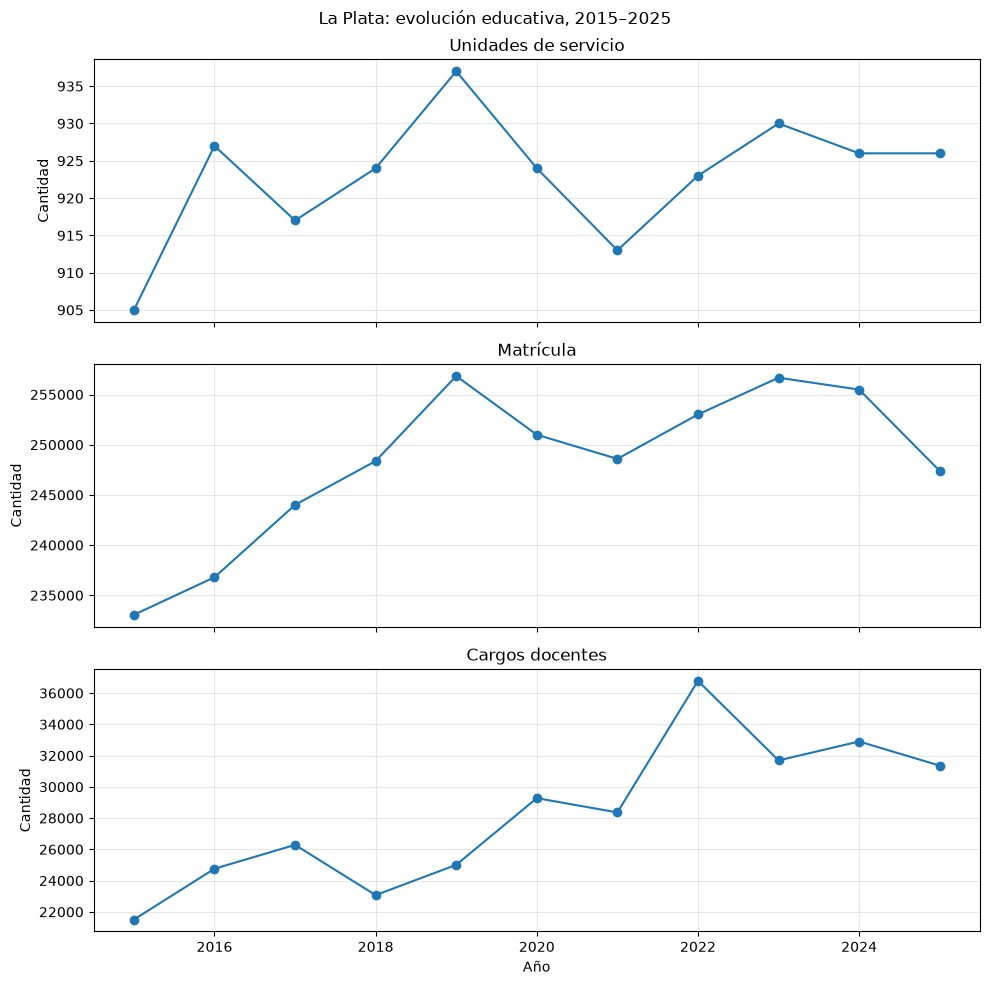

In [104]:
fig, axes = plt.subplots(3, 1, figsize=(10, 10), sharex=True)

variables = [
    ("unidades_de_servicio", "Unidades de servicio"),
    ("matricula", "Matrícula"),
    ("docentes", "Cargos docentes")
]

for ax, (variable, titulo) in zip(axes, variables):
    ax.plot(
        la_plata_anual["anio"],
        la_plata_anual[variable],
        marker="o"
    )
    ax.set_title(titulo)
    ax.set_ylabel("Cantidad")
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Año")

plt.suptitle("La Plata: evolución educativa, 2015–2025")
plt.tight_layout()
plt.show()

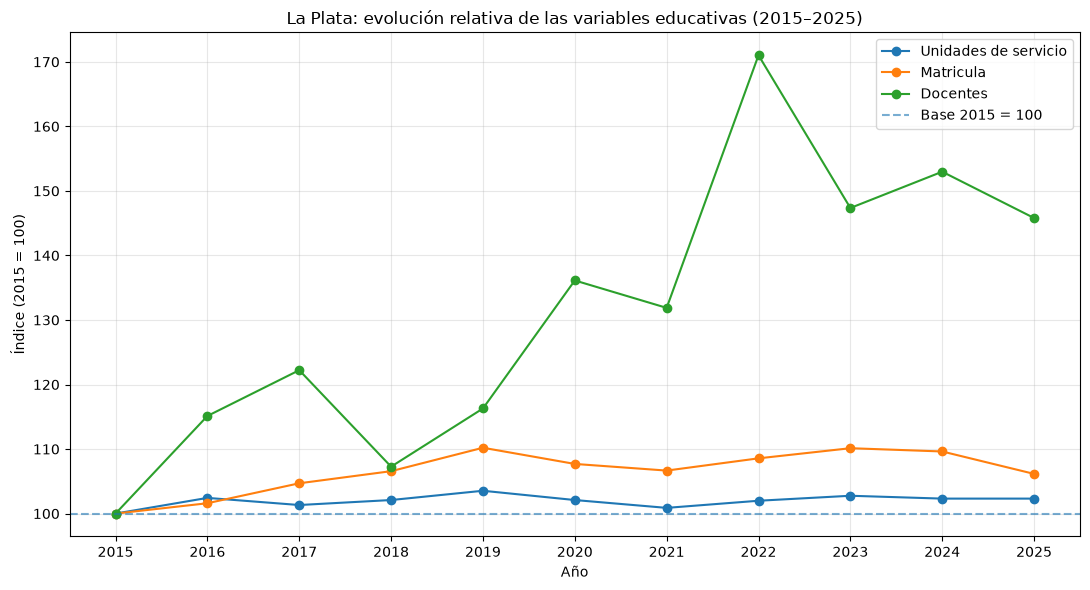

In [105]:
variables = [
    "unidades_de_servicio",
    "matricula",
    "docentes"
]

# Crear una tabla de índices, usando 2015 como base
indices = la_plata_anual[["anio"]].copy()

for variable in variables:
    valor_base = la_plata_anual.loc[
        la_plata_anual["anio"] == 2015, variable
    ].iloc[0]

    indices[variable] = (
        la_plata_anual[variable] / valor_base
    ) * 100

# Graficar las tres series en una misma escala
plt.figure(figsize=(11, 6))

for variable in variables:
    plt.plot(
        indices["anio"],
        indices[variable],
        marker="o",
        label=variable.replace("_", " ").capitalize()
    )

plt.axhline(100, linestyle="--", alpha=0.6, label="Base 2015 = 100")
plt.title("La Plata: evolución relativa de las variables educativas (2015–2025)")
plt.xlabel("Año")
plt.ylabel("Índice (2015 = 100)")
plt.xticks(indices["anio"])
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

#### ¿cómo evolucionó la cantidad de alumnos por cargo docente en La Plata entre 2015 y 2025?

In [106]:
la_plata_anual["matricula_por_cargo"] = (
    la_plata_anual["matricula"] / la_plata_anual["docentes"]
)

# Comparar el inicio, el año del salto y el final
la_plata_anual.loc[
    la_plata_anual["anio"].isin([2015, 2019, 2022, 2025]),
    ["anio", "matricula", "docentes", "matricula_por_cargo"]
].round(2)

,anio,matricula,docentes,matricula_por_cargo
65,2015,233062,21506.73,10.84
605,2019,256837,25009.70,10.27
1010,2022,253013,36781.40,6.88
1415,2025,247396,31356.82,7.89


- 2015–2019: la razón desciende moderadamente.
- 2019–2022: la caída se vuelve pronunciada, coincidiendo con el fuerte aumento registrado en los cargos docentes.
- 2022–2025: la razón vuelve a subir, aunque permanece por debajo de los valores de 2015 y 2019.
Entre 2015 y 2025, la razón pasó de 10,84 a 7,89, una reducción aproximada del 27,2 %

In [107]:
# Índice de matrícula por cargo, con base 2015 = 100
base = la_plata_anual.loc[
    la_plata_anual["anio"] == 2015,
    "matricula_por_cargo"
].iloc[0]

la_plata_anual["indice_matricula_por_cargo"] = (
    la_plata_anual["matricula_por_cargo"] / base
) * 100

la_plata_anual[
    ["anio", "matricula_por_cargo", "indice_matricula_por_cargo"]
].round(2)

,anio,matricula_por_cargo,indice_matricula_por_cargo
65,2015,10.84,100.00
200,2016,9.56,88.26
335,2017,9.28,85.66
470,2018,10.77,99.35
605,2019,10.27,94.77
740,2020,8.57,79.11
875,2021,8.76,80.88
1010,2022,6.88,63.48
1145,2023,8.10,74.74
1280,2024,7.77,71.66


#### ¿cuán excepcional fue La Plata?

In [108]:
# Variación interanual de los cargos docentes por municipio
cargos = df_municipal[
    ["anio", "municipio_nombre", "docentes"]
].copy()

cargos = cargos.sort_values(["municipio_nombre", "anio"])

cargos["variacion_pct_docentes"] = (
    cargos.groupby("municipio_nombre")["docentes"]
    .pct_change() * 100
)

# Comparar las variaciones entre 2021 y 2022
cambio_2022 = cargos[cargos["anio"] == 2022].copy()

cambio_2022[
    ["municipio_nombre", "variacion_pct_docentes"]
].sort_values(
    "variacion_pct_docentes",
    ascending=False
)

,municipio_nombre,variacion_pct_docentes
1073,Tres Lomas,64.922923
967,Chacabuco,44.987305
1015,Lezama,35.738355
962,Carlos Casares,35.037787
1010,La Plata,29.684123
...,...,...
1026,Mercedes,-13.251177
987,General Belgrano,-17.676257
972,Coronel Pringles,-18.901790
1042,Pinamar,-27.454717


La Plata registró un aumento del 29,68 % entre 2021 y 2022 y se ubicó en el quinto lugar del ranking que compartiste. Por encima aparecen Tres Lomas (+64,92 %), Chacabuco (+44,99 %), Lezama (+35,74 %) y Carlos Casares (+35,04 %).



In [109]:
# Clasificar la variación de cargos docentes en 2022
cambio_2022["direccion"] = cambio_2022[
    "variacion_pct_docentes"
].apply(
    lambda x: "Aumentó" if x > 0
    else "Disminuyó" if x < 0
    else "Sin cambio"
)

print(cambio_2022["direccion"].value_counts())

print(
    "\nMediana de la variación porcentual:",
    round(cambio_2022["variacion_pct_docentes"].median(), 2),
    "%"
)

print(
    "Variación de La Plata:",
    round(
        cambio_2022.loc[
            cambio_2022["municipio_nombre"] == "La Plata",
            "variacion_pct_docentes"
        ].iloc[0],
        2
    ),
    "%"
)

direccion
Aumentó      89
Disminuyó    46
Name: count, dtype: int64

Mediana de la variación porcentual: 2.06 %
Variación de La Plata: 29.68 %


Hay tres conclusiones descriptivas:
1. El aumento de cargos fue territorialmente extendido: ocurrió en 89 municipios.
2. La magnitud del aumento de La Plata fue excepcional respecto del municipio típico: su variación superó ampliamente la mediana.
3. La Plata no fue un caso aislado de aumento pronunciado: otros municipios también registraron incrementos importantes, incluso superiores.


#### Nota metodológica: evolución de los cargos docentes en 2022

El análisis de las variaciones interanuales de los cargos docentes muestra un comportamiento destacado en 2022. En La Plata, la variable aumentó un 29,68 % respecto de 2021. En el conjunto de los 135 municipios bonaerenses, 89 registraron aumentos y 46 disminuciones, mientras que la mediana de la variación porcentual fue del 2,06 %. La Plata se ubicó entre los cinco municipios con mayores aumentos.

Estos resultados indican que el crecimiento de los cargos fue frecuente en el territorio provincial, aunque la magnitud observada en La Plata superó ampliamente la variación municipal mediana. Sin embargo, la documentación disponible identifica la variable como «cargos docentes» sin detallar su definición operacional ni los criterios de contabilización empleados durante el período. Por este motivo, no es posible determinar con la información disponible si los cambios observados reflejan exclusivamente variaciones sustantivas o si intervienen cuestiones de registro o comparabilidad temporal.

En consecuencia, los valores se conservan sin modificaciones y las variaciones se presentan como resultados descriptivos. La evolución de los cargos docentes y de los indicadores derivados debe interpretarse con cautela hasta contar con información metodológica adicional.

#### ¿Cómo evolucionó la matrícula en relación con la cantidad de unidades de servicio?

In [110]:
# Calcular matrícula por unidad de servicio
la_plata_anual["matricula_por_unidad"] = (
    la_plata_anual["matricula"]
    / la_plata_anual["unidades_de_servicio"]
)

# Crear un índice con base 2015 = 100
base = la_plata_anual.loc[
    la_plata_anual["anio"] == 2015,
    "matricula_por_unidad"
].iloc[0]

la_plata_anual["indice_matricula_por_unidad"] = (
    la_plata_anual["matricula_por_unidad"] / base
) * 100

# Revisar la evolución completa
la_plata_anual[
    [
        "anio",
        "matricula",
        "unidades_de_servicio",
        "matricula_por_unidad",
        "indice_matricula_por_unidad"
    ]
].round(2)

,anio,matricula,unidades_de_servicio,matricula_por_unidad,indice_matricula_por_unidad
65,2015,233062,905,257.53,100.00
200,2016,236799,927,255.45,99.19
335,2017,244004,917,266.09,103.32
470,2018,248375,924,268.80,104.38
605,2019,256837,937,274.11,106.44
740,2020,250994,924,271.64,105.48
875,2021,248589,913,272.28,105.73
1010,2022,253013,923,274.12,106.44
1145,2023,256672,930,275.99,107.17
1280,2024,255491,926,275.91,107.14


Podemos afirmar que, en La Plata, la matrícula creció proporcionalmente más que las unidades de servicio entre 2015 y 2025. Como resultado, aumentó la razón agregada de matrícula por unidad.

#### ¿Cómo evolucionó la matrícula por cargo docente respecto de 2015, tomando 2015 como base 100?

In [111]:
la_plata_anual[
    [
        "anio",
        "indice_matricula_por_unidad",
        "indice_matricula_por_cargo"
    ]
].round(2)


,anio,indice_matricula_por_unidad,indice_matricula_por_cargo
65,2015,100.00,100.00
200,2016,99.19,88.26
335,2017,103.32,85.66
470,2018,104.38,99.35
605,2019,106.44,94.77
740,2020,105.48,79.11
875,2021,105.73,80.88
1010,2022,106.44,63.48
1145,2023,107.17,74.74
1280,2024,107.14,71.66


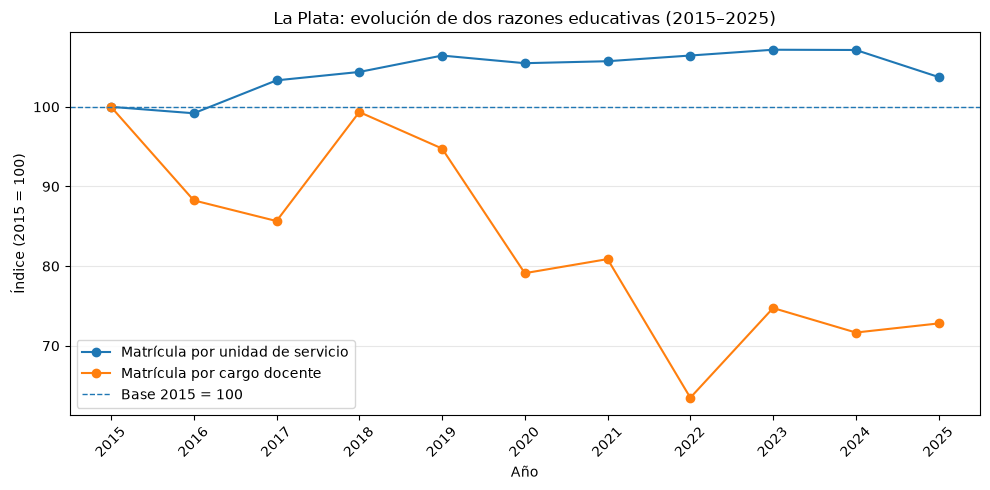

In [112]:
plt.figure(figsize=(10, 5))

plt.plot(
    la_plata_anual["anio"],
    la_plata_anual["indice_matricula_por_unidad"],
    marker="o",
    label="Matrícula por unidad de servicio"
)

plt.plot(
    la_plata_anual["anio"],
    la_plata_anual["indice_matricula_por_cargo"],
    marker="o",
    label="Matrícula por cargo docente"
)

plt.axhline(
    y=100,
    linestyle="--",
    linewidth=1,
    label="Base 2015 = 100"
)

plt.title("La Plata: evolución de dos razones educativas (2015–2025)")
plt.xlabel("Año")
plt.ylabel("Índice (2015 = 100)")
plt.xticks(la_plata_anual["anio"], rotation=45)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [113]:
variables = [
    "unidades_de_servicio",
    "matricula",
    "docentes"
]

resumen_la_plata = pd.DataFrame({
    "valor_2015": [
        la_plata_anual.loc[
            la_plata_anual["anio"] == 2015, variable
        ].iloc[0]
        for variable in variables
    ],
    "valor_2025": [
        la_plata_anual.loc[
            la_plata_anual["anio"] == 2025, variable
        ].iloc[0]
        for variable in variables
    ]
}, index=variables)

resumen_la_plata["cambio_absoluto"] = (
    resumen_la_plata["valor_2025"]
    - resumen_la_plata["valor_2015"]
)

resumen_la_plata["cambio_porcentual"] = (
    resumen_la_plata["cambio_absoluto"]
    / resumen_la_plata["valor_2015"]
    * 100
)

resumen_la_plata.round(2)


,valor_2015,valor_2025,cambio_absoluto,cambio_porcentual
unidades_de_servicio,905.00,926.00,21.00,2.32
matricula,233062.00,247396.00,14334.00,6.15
docentes,21506.73,31356.82,9850.08,45.80


### La Plata: evolución de unidades de servicio, matrícula y cargos docentes (2015–2025)

Entre 2015 y 2025, la matrícula educativa registrada en el partido de La Plata aumentó de 233.062 a 247.396, lo que representa un incremento del 6,15 %. En el mismo período, las unidades de servicio pasaron de 905 a 926 (+2,32 %). En consecuencia, la razón agregada de matrícula por unidad de servicio aumentó de 257,53 a 267,17, equivalente a una variación del 3,74 %.

La evolución anual muestra que esta razón alcanzó su máximo en 2024 y descendió en 2025, aunque permaneció por encima del valor de 2015. Por su parte, la cantidad de cargos docentes pasó de 21.506,73 a 31.356,82 (+45,80 %). Esta variación se asocia con una reducción de la razón agregada de matrícula por cargo docente entre los extremos del período.

Los resultados describen trayectorias diferentes entre matrícula, unidades de servicio y cargos docentes. No permiten, por sí solos, establecer cambios en el tamaño de las clases, las condiciones de enseñanza, la dotación efectiva de personas docentes o la infraestructura física. La interpretación de la serie de cargos requiere especial cautela debido a sus fluctuaciones interanuales y a la necesidad de precisar la definición operativa de la variable.

#### ¿Cómo se compara el crecimiento de la matrícula de La Plata entre 2015 y 2025 con el de los otros municipios de la provincia?

In [114]:
matricula_extremos = (
    df_municipal[
        df_municipal["anio"].isin([2015, 2025])
    ]
    .pivot(
        index="municipio_nombre",
        columns="anio",
        values="matricula"
    )
    .reset_index()
)

matricula_extremos.head()

anio,municipio_nombre,2015,2025
0,Adolfo Alsina,5500,5551
1,Alberti,4055,4016
2,Almirante Brown,152622,158864
3,Arrecifes,9225,9677
4,Avellaneda,116019,110054


¿Cuánto aumentó o disminuyó proporcionalmente la matrícula de cada municipio entre 2015 y 2025?

In [115]:

matricula_extremos["variacion_matricula_pct"] = (
    (
        matricula_extremos[2025]
        - matricula_extremos[2015]
    )
    / matricula_extremos[2015]
    * 100
)

matricula_extremos[
    [
        "municipio_nombre",
        2015,
        2025,
        "variacion_matricula_pct"
    ]
].round(2).head(10)


anio,municipio_nombre,2015,2025,variacion_matricula_pct
0,Adolfo Alsina,5500,5551,0.93
1,Alberti,4055,4016,-0.96
2,Almirante Brown,152622,158864,4.09
3,Arrecifes,9225,9677,4.90
4,Avellaneda,116019,110054,-5.14
5,Ayacucho,9952,8770,-11.88
6,Azul,24594,22895,-6.91
7,Bahía Blanca,98525,92460,-6.16
8,Balcarce,14438,14451,0.09
9,Baradero,12721,12588,-1.05


¿Cuántos municipios aumentaron y cuántos redujeron su matrícula? ¿Cuál es la variación porcentual mediana? ¿Cómo se ubica La Plata respecto del conjunto?

In [116]:
print(
    matricula_extremos["variacion_matricula_pct"]
    .describe()
    .round(2)
)

print(
    "\nMunicipios con aumento:",
    (matricula_extremos["variacion_matricula_pct"] > 0).sum()
)

print(
    "Municipios con descenso:",
    (matricula_extremos["variacion_matricula_pct"] < 0).sum()
)

print(
    "Municipios sin variación:",
    (matricula_extremos["variacion_matricula_pct"] == 0).sum()
)

count    135.00
mean       4.30
std       11.58
min      -19.06
25%       -2.56
50%        1.70
75%        9.46
max       47.94
Name: variacion_matricula_pct, dtype: float64

Municipios con aumento: 82
Municipios con descenso: 53
Municipios sin variación: 0


In [117]:
la_plata_variacion = matricula_extremos.loc[
    matricula_extremos["municipio_nombre"] == "La Plata",
    "variacion_matricula_pct"
].iloc[0]

municipios_mayor = (
    matricula_extremos["variacion_matricula_pct"]
    > la_plata_variacion
).sum()

municipios_menor = (
    matricula_extremos["variacion_matricula_pct"]
    < la_plata_variacion
).sum()

print(f"Variación de La Plata: {la_plata_variacion:.2f}%")
print("Municipios con mayor crecimiento:", municipios_mayor)
print("Municipios con menor crecimiento:", municipios_menor)


Variación de La Plata: 6.15%
Municipios con mayor crecimiento: 42
Municipios con menor crecimiento: 92


La Plata aumentó su matrícula un 6,15 % entre 2015 y 2025. De los otros 134 municipios, 92 tuvieron una variación menor y 42 tuvieron una mayor. Por lo tanto, La Plata se ubicó por encima de aproximadamente el 68,7 % de los municipios en términos de crecimiento de matrícula.

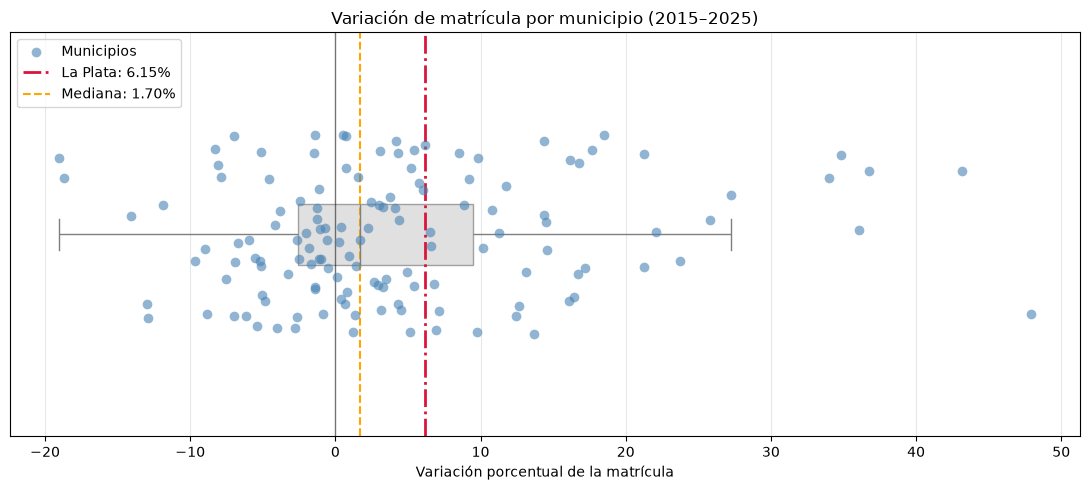

In [118]:
fig, ax = plt.subplots(figsize=(11, 5))

# 1. Todos los municipios como puntos
sns.stripplot(
    x=matricula_extremos["variacion_matricula_pct"],
    ax=ax,
    color="steelblue",
    alpha=0.6,
    size=7,
    jitter=0.25,
    label="Municipios",
)

# 2. Caja resumen debajo (mediana, cuartiles, outliers)
sns.boxplot(
    x=matricula_extremos["variacion_matricula_pct"],
    ax=ax,
    width=0.15,
    color="lightgray",
    fliersize=0,
    boxprops=dict(alpha=0.7),
)

# 3. La Plata destacada en rojo
ax.axvline(
    la_plata_variacion,
    color="crimson",
    linestyle="-.",
    linewidth=2,
    label=f"La Plata: {la_plata_variacion:.2f}%"
)

# 4. Línea vertical en 0 (referencia)
ax.axvline(0, color="black", linewidth=1, alpha=0.5)

# 5. Línea de mediana
mediana = matricula_extremos["variacion_matricula_pct"].median()
ax.axvline(mediana, color="orange", linestyle="--", linewidth=1.5,
           label=f"Mediana: {mediana:.2f}%")

ax.set_title("Variación de matrícula por municipio (2015–2025)")
ax.set_xlabel("Variación porcentual de la matrícula")
ax.set_yticks([])  # no hace falta eje Y
ax.legend(loc="upper left")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

¿Cuánto aumentaron o disminuyeron las unidades de servicio en cada municipio entre 2015 y 2025?

In [119]:
unidades_extremos = (
    df_municipal[
        df_municipal["anio"].isin([2015, 2025])
    ]
    .pivot(
        index="municipio_nombre",
        columns="anio",
        values="unidades_de_servicio"
    )
    .reset_index()
)

unidades_extremos.head()


anio,municipio_nombre,2015,2025
0,Adolfo Alsina,83,73
1,Alberti,42,47
2,Almirante Brown,546,537
3,Arrecifes,65,65
4,Avellaneda,439,404


In [120]:
unidades_extremos["variacion_unidades_pct"] = (
    (
        unidades_extremos[2025]
        - unidades_extremos[2015]
    )
    / unidades_extremos[2015]
    * 100
)

unidades_extremos[
    [
        "municipio_nombre",
        2015,
        2025,
        "variacion_unidades_pct"
    ]
].round(2).head(10)


anio,municipio_nombre,2015,2025,variacion_unidades_pct
0,Adolfo Alsina,83,73,-12.05
1,Alberti,42,47,11.90
2,Almirante Brown,546,537,-1.65
3,Arrecifes,65,65,0.00
4,Avellaneda,439,404,-7.97
5,Ayacucho,84,86,2.38
6,Azul,184,169,-8.15
7,Bahía Blanca,435,414,-4.83
8,Balcarce,127,119,-6.30
9,Baradero,98,98,0.00


¿Los municipios donde aumentó la matrícula también tendieron a aumentar las unidades de servicio?

In [128]:
comparacion_municipal = matricula_extremos[
    ["municipio_nombre", "variacion_matricula_pct"]
].merge(
    unidades_extremos[
        ["municipio_nombre", "variacion_unidades_pct"]
    ],
    on="municipio_nombre",
    how="outer",
    validate="one_to_one",
    indicator=True
)

print(comparacion_municipal["_merge"].value_counts())
print("Filas:", len(comparacion_municipal))

comparacion_municipal.head(20)

_merge
both          135
left_only       0
right_only      0
Name: count, dtype: int64
Filas: 135


anio,municipio_nombre,variacion_matricula_pct,variacion_unidades_pct,_merge
0,Adolfo Alsina,0.927273,-12.048193,both
1,Alberti,-0.961776,11.904762,both
2,Almirante Brown,4.089843,-1.648352,both
3,Arrecifes,4.899729,0.000000,both
4,Avellaneda,-5.141399,-7.972665,both
5,Ayacucho,-11.877010,2.380952,both
6,Azul,-6.908189,-8.152174,both
7,Bahía Blanca,-6.155798,-4.827586,both
8,Balcarce,0.090040,-6.299213,both
9,Baradero,-1.045515,0.000000,both


In [129]:
condiciones = [
    (comparacion_municipal["variacion_matricula_pct"] > 0)
    & (comparacion_municipal["variacion_unidades_pct"] > 0),

    (comparacion_municipal["variacion_matricula_pct"] < 0)
    & (comparacion_municipal["variacion_unidades_pct"] < 0),

    (comparacion_municipal["variacion_matricula_pct"] > 0)
    & (comparacion_municipal["variacion_unidades_pct"] < 0),

    (comparacion_municipal["variacion_matricula_pct"] < 0)
    & (comparacion_municipal["variacion_unidades_pct"] > 0),

    (comparacion_municipal["variacion_unidades_pct"] == 0)
    & (comparacion_municipal["variacion_matricula_pct"] > 0),

    (comparacion_municipal["variacion_unidades_pct"] == 0)
    & (comparacion_municipal["variacion_matricula_pct"] < 0),

    (comparacion_municipal["variacion_matricula_pct"] == 0)
    & (comparacion_municipal["variacion_unidades_pct"] > 0),

    (comparacion_municipal["variacion_matricula_pct"] == 0)
    & (comparacion_municipal["variacion_unidades_pct"] < 0),

    (comparacion_municipal["variacion_matricula_pct"] == 0)
    & (comparacion_municipal["variacion_unidades_pct"] == 0),
]

categorias = [
    "Ambas aumentan",
    "Ambas disminuyen",
    "Matrícula sube, unidades bajan",
    "Matrícula baja, unidades suben",
    "Unidades sin cambio, matrícula sube",
    "Unidades sin cambio, matrícula baja",
    "Matrícula sin cambio, unidades suben",
    "Matrícula sin cambio, unidades bajan",
    "Ambas sin cambio",
]

comparacion_municipal["trayectoria"] = np.select(
    condiciones,
    categorias,
    default="Revisar clasificación"
)

comparacion_municipal["trayectoria"].value_counts()

trayectoria
Ambas disminuyen                       46
Matrícula sube, unidades bajan         42
Ambas aumentan                         32
Unidades sin cambio, matrícula sube     8
Matrícula baja, unidades suben          5
Unidades sin cambio, matrícula baja     2
Name: count, dtype: int64

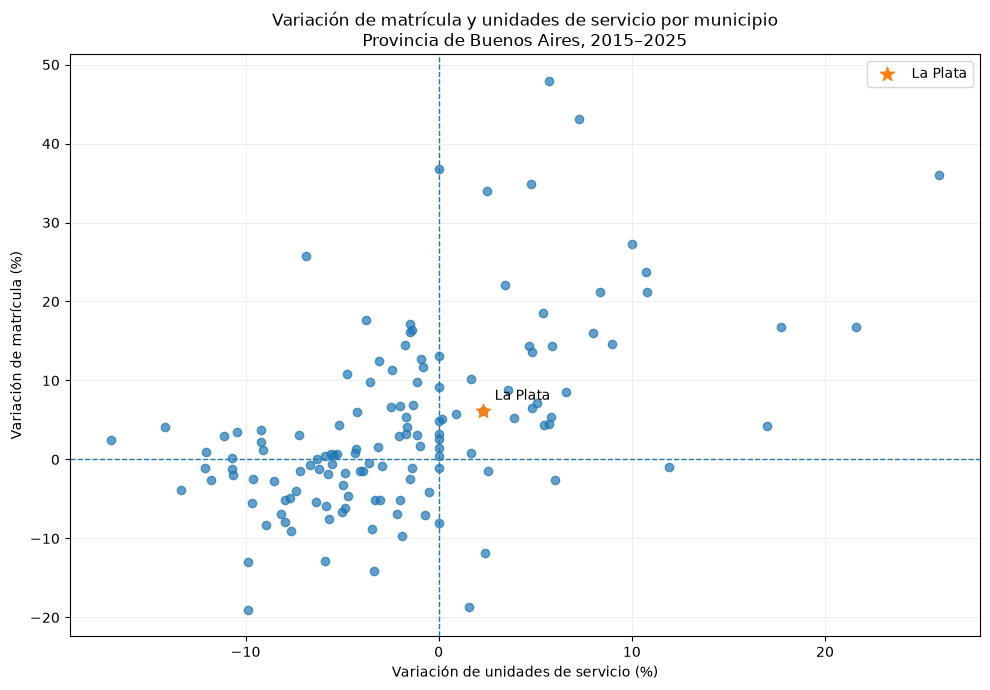

In [131]:
import matplotlib.pyplot as plt

# Identificamos el registro de La Plata
la_plata = comparacion_municipal[
    comparacion_municipal["municipio_nombre"] == "La Plata"
]

# Comprobación antes de graficar
assert len(la_plata) == 1, "La Plata debe aparecer exactamente una vez"

fig, ax = plt.subplots(figsize=(10, 7))

# Un punto representa un municipio
ax.scatter(
    comparacion_municipal["variacion_unidades_pct"],
    comparacion_municipal["variacion_matricula_pct"],
    alpha=0.7
)

# Líneas de referencia: variación nula
ax.axhline(y=0, linestyle="--", linewidth=1)
ax.axvline(x=0, linestyle="--", linewidth=1)

# Destacamos La Plata
ax.scatter(
    la_plata["variacion_unidades_pct"],
    la_plata["variacion_matricula_pct"],
    s=110,
    marker="*",
    label="La Plata"
)

ax.annotate(
    "La Plata",
    (
        la_plata["variacion_unidades_pct"].iloc[0],
        la_plata["variacion_matricula_pct"].iloc[0]
    ),
    xytext=(8, 8),
    textcoords="offset points"
)

ax.set_title(
    "Variación de matrícula y unidades de servicio por municipio\n"
    "Provincia de Buenos Aires, 2015–2025"
)
ax.set_xlabel("Variación de unidades de servicio (%)")
ax.set_ylabel("Variación de matrícula (%)")
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

¿Qué municipios registraron las mayores subas y las mayores bajas en cada variable?

In [132]:
columnas = [
    "municipio_nombre",
    "variacion_matricula_pct",
    "variacion_unidades_pct",
]

print("MAYORES AUMENTOS DE MATRÍCULA")
display(
    comparacion_municipal
    .nlargest(5, "variacion_matricula_pct")[columnas]
    .round(2)
)

print("MAYORES DISMINUCIONES DE MATRÍCULA")
display(
    comparacion_municipal
    .nsmallest(5, "variacion_matricula_pct")[columnas]
    .round(2)
)

print("MAYORES AUMENTOS DE UNIDADES")
display(
    comparacion_municipal
    .nlargest(5, "variacion_unidades_pct")[columnas]
    .round(2)
)

print("MAYORES DISMINUCIONES DE UNIDADES")
display(
    comparacion_municipal
    .nsmallest(5, "variacion_unidades_pct")[columnas]
    .round(2)
)

MAYORES AUMENTOS DE MATRÍCULA


anio,municipio_nombre,variacion_matricula_pct,variacion_unidades_pct
95,Pila,47.94,5.71
51,General Rodríguez,43.14,7.26
124,Tordillo,36.73,0.00
119,San Vicente,36.04,25.88
84,Monte Hermoso,34.86,4.76


MAYORES DISMINUCIONES DE MATRÍCULA


anio,municipio_nombre,variacion_matricula_pct,variacion_unidades_pct
115,San Isidro,-19.06,-9.88
18,Carlos Tejedor,-18.72,1.59
128,Tres Lomas,-14.11,-3.33
131,Vicente López,-13.00,-9.88
86,Morón,-12.91,-5.87


MAYORES AUMENTOS DE UNIDADES


anio,municipio_nombre,variacion_matricula_pct,variacion_unidades_pct
119,San Vicente,36.04,25.88
97,Pinamar,16.81,21.62
36,Ezeiza,16.74,17.72
132,Villa Gesell,4.28,17.02
1,Alberti,-0.96,11.90


MAYORES DISMINUCIONES DE UNIDADES


anio,municipio_nombre,variacion_matricula_pct,variacion_unidades_pct
133,Villarino,2.45,-16.96
91,Patagones,4.15,-14.17
89,Nueve de Julio,-3.81,-13.33
113,San Cayetano,-1.11,-12.12
0,Adolfo Alsina,0.93,-12.05


In [133]:
variaciones_absolutas = (
    df_municipal[df_municipal["anio"].isin([2015, 2025])]
    .pivot(
        index="municipio_nombre",
        columns="anio",
        values=["matricula", "unidades_de_servicio"]
    )
)

variaciones_absolutas.columns = [
    f"{variable}_{anio}"
    for variable, anio in variaciones_absolutas.columns
]

variaciones_absolutas = variaciones_absolutas.reset_index()

variaciones_absolutas["cambio_matricula"] = (
    variaciones_absolutas["matricula_2025"]
    - variaciones_absolutas["matricula_2015"]
)

variaciones_absolutas["cambio_unidades"] = (
    variaciones_absolutas["unidades_de_servicio_2025"]
    - variaciones_absolutas["unidades_de_servicio_2015"]
)

variaciones_absolutas.head()

,municipio_nombre,matricula_2015,matricula_2025,unidades_de_servicio_2015,unidades_de_servicio_2025,cambio_matricula,cambio_unidades
0,Adolfo Alsina,5500,5551,83,73,51,-10
1,Alberti,4055,4016,42,47,-39,5
2,Almirante Brown,152622,158864,546,537,6242,-9
3,Arrecifes,9225,9677,65,65,452,0
4,Avellaneda,116019,110054,439,404,-5965,-35


In [134]:
print("Filas:", len(variaciones_absolutas))
print(
    "Municipios duplicados:",
    variaciones_absolutas["municipio_nombre"].duplicated().sum()
)
print(
    "Valores faltantes:",
    variaciones_absolutas[
        [
            "matricula_2015",
            "matricula_2025",
            "unidades_de_servicio_2015",
            "unidades_de_servicio_2025",
        ]
    ].isna().sum()
)

Filas: 135
Municipios duplicados: 0
Valores faltantes: matricula_2015               0
matricula_2025               0
unidades_de_servicio_2015    0
unidades_de_servicio_2025    0
dtype: int64


¿Qué municipios registraron los mayores aumentos y disminuciones en cantidad de estudiantes? ¿Y cuáles tuvieron los mayores cambios netos en unidades de servicio?

In [135]:
columnas = [
    "municipio_nombre",
    "cambio_matricula",
    "cambio_unidades",
]

print("MAYORES AUMENTOS ABSOLUTOS DE MATRÍCULA")
display(
    variaciones_absolutas
    .nlargest(10, "cambio_matricula")[columnas]
)

print("MAYORES DISMINUCIONES ABSOLUTAS DE MATRÍCULA")
display(
    variaciones_absolutas
    .nsmallest(10, "cambio_matricula")[columnas]
)

print("MAYORES AUMENTOS ABSOLUTOS DE UNIDADES")
display(
    variaciones_absolutas
    .nlargest(10, "cambio_unidades")[columnas]
)

print("MAYORES DISMINUCIONES ABSOLUTAS DE UNIDADES")
display(
    variaciones_absolutas
    .nsmallest(10, "cambio_unidades")[columnas]
)

MAYORES AUMENTOS ABSOLUTOS DE MATRÍCULA


,municipio_nombre,cambio_matricula,cambio_unidades
64,La Matanza,20913,2
85,Moreno,18068,-4
51,General Rodríguez,15704,9
96,Pilar,15158,18
65,La Plata,14334,21
33,Escobar,10999,24
119,San Vicente,9613,22
36,Ezeiza,9595,28
2,Almirante Brown,6242,-9
34,Esteban Echeverría,6014,-7


MAYORES DISMINUCIONES ABSOLUTAS DE MATRÍCULA


,municipio_nombre,cambio_matricula,cambio_unidades
115,San Isidro,-16973,-40
86,Morón,-13875,-25
131,Vicente López,-8862,-33
50,General Pueyrredón,-7861,-59
52,General San Martín,-7482,-9
7,Bahía Blanca,-6065,-21
4,Avellaneda,-5965,-35
129,Tres de Febrero,-4131,-7
59,Ituzaingo,-3321,-11
90,Olavarría,-2920,-13


MAYORES AUMENTOS ABSOLUTOS DE UNIDADES


,municipio_nombre,cambio_matricula,cambio_unidades
36,Ezeiza,9595,28
33,Escobar,10999,24
119,San Vicente,9613,22
65,La Plata,14334,21
96,Pilar,15158,18
51,General Rodríguez,15704,9
97,Pinamar,1716,8
98,Presidente Perón,5951,8
132,Villa Gesell,496,8
81,Mercedes,1540,7


MAYORES DISMINUCIONES ABSOLUTAS DE UNIDADES


,municipio_nombre,cambio_matricula,cambio_unidades
50,General Pueyrredón,-7861,-59
37,Florencio Varela,4565,-43
115,San Isidro,-16973,-40
101,Quilmes,-2168,-38
4,Avellaneda,-5965,-35
66,Lanús,-819,-33
131,Vicente López,-8862,-33
86,Morón,-13875,-25
7,Bahía Blanca,-6065,-21
10,Berazategui,-609,-21


In [136]:
print(
    "Cambio municipal acumulado de matrícula:",
    variaciones_absolutas["cambio_matricula"].sum()
)

print(
    "Cambio municipal acumulado de unidades:",
    variaciones_absolutas["cambio_unidades"].sum()
)

Cambio municipal acumulado de matrícula: 87316
Cambio municipal acumulado de unidades: -618


¿cómo se distribuye el aumento neto de matrícula?

In [137]:
cambio_provincial_matricula = (
    variaciones_absolutas["cambio_matricula"].sum()
)

variaciones_absolutas["contribucion_cambio_matricula_pct"] = (
    variaciones_absolutas["cambio_matricula"]
    / cambio_provincial_matricula
    * 100
)

variaciones_absolutas.nlargest(
    10, "contribucion_cambio_matricula_pct"
)[
    [
        "municipio_nombre",
        "cambio_matricula",
        "contribucion_cambio_matricula_pct",
    ]
].round(2)

,municipio_nombre,cambio_matricula,contribucion_cambio_matricula_pct
64,La Matanza,20913,23.95
85,Moreno,18068,20.69
51,General Rodríguez,15704,17.99
96,Pilar,15158,17.36
65,La Plata,14334,16.42
33,Escobar,10999,12.60
119,San Vicente,9613,11.01
36,Ezeiza,9595,10.99
2,Almirante Brown,6242,7.15
34,Esteban Echeverría,6014,6.89


In [138]:
print(
    "Suma de contribuciones municipales (%):",
    variaciones_absolutas[
        "contribucion_cambio_matricula_pct"
    ].sum()
)

top_10_matricula = variaciones_absolutas.nlargest(
    10, "contribucion_cambio_matricula_pct"
)

print(
    "Contribución conjunta de los 10 municipios (%):",
    top_10_matricula[
        "contribucion_cambio_matricula_pct"
    ].sum()
)

print(
    "Suma de cambios absolutos de esos 10 municipios:",
    top_10_matricula["cambio_matricula"].sum()
)

Suma de contribuciones municipales (%): 100.0
Contribución conjunta de los 10 municipios (%): 145.03641944202667
Suma de cambios absolutos de esos 10 municipios: 126640


### 1. Evolución provincial: un crecimiento neto moderado

Entre 2015 y 2025, la matrícula educativa de la Provincia de Buenos Aires pasó de 4.914.177 a 5.001.493, lo que representa un incremento neto de 87.316 registros, equivalente aproximadamente al 1,78 % del valor inicial.

Este resultado describe un crecimiento moderado de la matrícula en el conjunto del período, pero no implica una trayectoria ascendente continua. La serie anual muestra que la matrícula alcanzó su máximo en 2019 y luego descendió durante los años siguientes, con una recuperación hasta 2023 y nuevas disminuciones en 2024 y 2025. Por lo tanto, la comparación entre los extremos del período resume una evolución más compleja que la que expresa por sí sola la variación porcentual acumulada.

En paralelo, las unidades de servicio pasaron de 22.137 en 2015 a 21.519 en 2025: una disminución neta de 618 unidades, equivalente aproximadamente al 2,79 %. La combinación de una matrícula ligeramente mayor y una cantidad menor de unidades de servicio constituye un patrón relevante para profundizar el análisis territorial. Sin embargo, estos datos agregados no permiten concluir que hayan cerrado establecimientos físicos ni que se hayan producido cambios determinados en la organización escolar. Las unidades de servicio no deben equipararse automáticamente con edificios o escuelas únicas.

### 2. Diferencias municipales en la evolución de la matrícula

La evolución provincial oculta trayectorias municipales heterogéneas. De los 135 municipios bonaerenses, 82 registraron un aumento de matrícula entre 2015 y 2025, mientras que 53 presentaron una disminución. En términos relativos, aproximadamente el 60,7 % de los municipios mostró un incremento.

La variación porcentual municipal tuvo una media de 4,30 % y una mediana de 1,70 %. La diferencia entre ambas medidas sugiere que algunos aumentos elevados influyen en la media y que la distribución de las variaciones no debe resumirse únicamente con un promedio. Los valores oscilaron entre una disminución del 19,06 % y un aumento del 47,94 %.

La Plata registró un incremento del 6,15 %, superior tanto a la media como a la mediana municipal. Su evolución se ubicó por encima de la de 42 municipios y por debajo de la de los otros 92. Esto sitúa al distrito en una posición de crecimiento relativo positivo, aunque no entre los municipios con las mayores variaciones porcentuales.

Estos resultados muestran que el crecimiento provincial no se distribuyó uniformemente en el territorio. Algunos municipios experimentaron aumentos importantes, mientras que otros registraron contracciones. La identificación de estas diferencias constituye un punto de partida para estudiar patrones territoriales, sin atribuirles causas que todavía no fueron investigadas.

### 3. La contribución de los municipios al cambio neto provincial

El análisis de los cambios absolutos permite complementar la comparación porcentual. Entre los municipios con mayores aumentos absolutos de matrícula se encuentran La Matanza (+20.913), Moreno (+18.068), General Rodríguez (+15.704), Pilar (+15.158) y La Plata (+14.334). En sentido contrario, entre las mayores disminuciones se encuentran San Isidro (−16.973), Morón (−13.875) y Vicente López (−8.862).

La diferencia entre cambios absolutos y porcentuales es importante para interpretar estos resultados. Una variación porcentual elevada no necesariamente representa el mayor aumento en cantidad de alumnos, porque los municipios parten de volúmenes de matrícula distintos. Por eso, ambas medidas responden preguntas diferentes y resultan complementarias.

Los diez municipios con mayores aumentos absolutos sumaron un incremento conjunto de 126.640 registros, equivalente al 145,04 % del cambio neto provincial de 87.316. Este porcentaje supera el 100 % porque las disminuciones registradas en otros municipios compensaron parcialmente esos aumentos. No representa la proporción de la matrícula total provincial localizada en esos diez distritos, sino la relación entre su incremento acumulado y el saldo neto provincial.

La suma de las contribuciones porcentuales de los 135 municipios es del 100 %, lo que confirma la consistencia aritmética de este cálculo cuando se utiliza como denominador el cambio neto provincial. Además, la suma de los cambios absolutos municipales coincide con la variación provincial. Esta concordancia constituye una validación interna relevante de los datos utilizados para la comparación entre 2015 y 2025.

### 4. La Plata en el contexto provincial

La matrícula de La Plata pasó de 233.062 en 2015 a 247.396 en 2025, con un incremento neto de 14.334 registros (+6,15 %). Las unidades de servicio aumentaron de 905 a 926 (+2,32 %). Por su parte, los cargos docentes pasaron de aproximadamente 21.507 a 31.357 (+45,80 %).

La trayectoria de matrícula de La Plata tampoco fue lineal: alcanzó un máximo de 256.837 en 2019, volvió a aproximarse a ese nivel en 2023 y descendió durante los dos años siguientes. Por ello, el crecimiento acumulado entre los extremos del período debe interpretarse junto con la evolución anual.

La comparación entre matrícula y unidades de servicio permite calcular una razón agregada que pasó de 257,53 registros de matrícula por unidad en 2015 a 267,17 en 2025. Este indicador aumentó aproximadamente un 3,74 %. No debe interpretarse como la matrícula promedio de cada escuela física, ya que una unidad de servicio no equivale necesariamente a un establecimiento único y el cociente agregado no describe por sí solo la distribución interna de la matrícula.

También se observó un incremento importante de los cargos docentes en el período. No obstante, los cargos no equivalen a personas: un docente puede ocupar más de un cargo y la variable puede presentar valores decimales. Por ello, la razón entre matrícula y cargos es un indicador agregado que requiere cautela y no debe presentarse como cantidad real de alumnos por docente ni como medida directa del tamaño de las clases.

### 5. Alcances y límites de esta primera etapa

Los resultados permiten establecer tres hallazgos descriptivos: la matrícula provincial tuvo un incremento neto moderado entre 2015 y 2025; las trayectorias municipales fueron heterogéneas; y La Plata registró un crecimiento de matrícula superior al promedio y a la mediana de las variaciones porcentuales municipales.

La comparación entre matrícula, unidades de servicio y cargos también muestra que estas dimensiones evolucionaron a ritmos diferentes. Sin embargo, las diferencias observadas no identifican por sí mismas los mecanismos que las produjeron. Para avanzar hacia explicaciones será necesario incorporar documentación sobre las definiciones de las variables, examinar la comparabilidad temporal y desarrollar análisis adicionales.

En particular, la evolución de los cargos presenta variaciones anuales importantes que requieren una revisión específica antes de formular conclusiones sustantivas. También será necesario analizar los cambios absolutos y porcentuales de las unidades de servicio por municipio, distinguir patrones territoriales y documentar los límites de cada indicador.

En consecuencia, estos resultados deben considerarse una primera caracterización descriptiva del sistema educativo bonaerense, no una explicación causal de sus transformaciones. Su valor reside en identificar tendencias, diferencias territoriales y nuevas preguntas de investigación que puedan abordarse de manera sistemática.

#### cómo cambiaron las unidades de servicio entre 2015 y 2025 y qué relación descriptiva tuvieron esos cambios con la matrícula

¿en qué municipios aumentó o disminuyó más la cantidad de unidades de servicio, y qué ocurrió con su matrícula en el mismo período?

In [141]:
# Diez municipios con mayores aumentos
top_10_unidades = variaciones_absolutas.nlargest(
    10, "cambio_unidades"
)

print(
    top_10_unidades[
        [
            "municipio_nombre",
            "cambio_unidades",
            "cambio_matricula"
        ]
    ].to_string(index=False)
)

 municipio_nombre  cambio_unidades  cambio_matricula
           Ezeiza               28              9595
          Escobar               24             10999
      San Vicente               22              9613
         La Plata               21             14334
            Pilar               18             15158
General Rodríguez                9             15704
          Pinamar                8              1716
 Presidente Perón                8              5951
     Villa Gesell                8               496
         Mercedes                7              1540


En este grupo de municipios, los aumentos de unidades de servicio coexistieron con aumentos de matrícula entre 2015 y 2025.
Pero hay diferencias importantes. Villa Gesell, por ejemplo, registró ocho unidades adicionales y un aumento de matrícula de 496; General Rodríguez registró nueve unidades adicionales y un aumento de 15.704. Por lo tanto, el cambio en unidades no se traduce en un incremento uniforme de matrícula entre los municipios.

In [142]:
# Diez municipios con mayores disminuciones
bottom_10_unidades = variaciones_absolutas.nsmallest(
    10, "cambio_unidades"
)

print(
    bottom_10_unidades[
        [
            "municipio_nombre",
            "cambio_unidades",
            "cambio_matricula"
        ]
    ].to_string(index=False)
)

  municipio_nombre  cambio_unidades  cambio_matricula
General Pueyrredón              -59             -7861
  Florencio Varela              -43              4565
        San Isidro              -40            -16973
           Quilmes              -38             -2168
        Avellaneda              -35             -5965
             Lanús              -33              -819
     Vicente López              -33             -8862
             Morón              -25            -13875
      Bahía Blanca              -21             -6065
       Berazategui              -21              -609


Acá aparece una excepción especialmente relevante: Florencio Varela perdió 43 unidades de servicio, pero su matrícula aumentó en 4.565 registros.
En los otros nueve municipios de esta tabla, disminuyeron tanto las unidades de servicio como la matrícula. Sin embargo, eso no significa que ambas variables hayan evolucionado en proporciones equivalentes, ni que una explique la otra.

¿Cómo se distribuyen los municipios según la dirección de los cambios de matrícula y de unidades de servicio?

In [143]:
frecuencias_trayectoria = (
    comparacion_municipal["trayectoria"]
    .value_counts()
)

porcentajes_trayectoria = (
    comparacion_municipal["trayectoria"]
    .value_counts(normalize=True)
    .mul(100)
    .round(1)
)

resumen_trayectorias = pd.DataFrame({
    "municipios": frecuencias_trayectoria,
    "porcentaje": porcentajes_trayectoria
})

print(resumen_trayectorias)

                                     municipios  porcentaje
trayectoria                                                
Ambas disminuyen                             46        34.1
Matrícula sube, unidades bajan               42        31.1
Ambas aumentan                               32        23.7
Unidades sin cambio, matrícula sube           8         5.9
Matrícula baja, unidades suben                5         3.7
Unidades sin cambio, matrícula baja           2         1.5


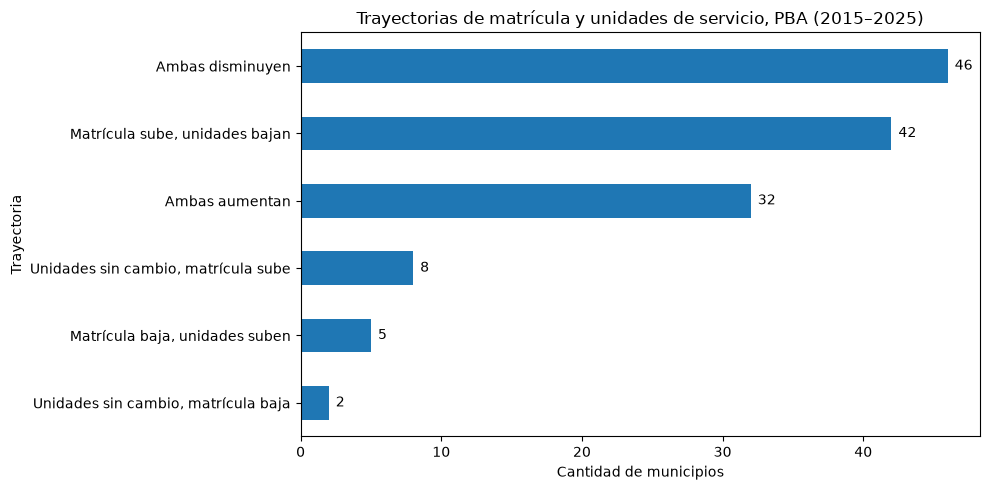

In [144]:
resumen_grafico = resumen_trayectorias.sort_values(
    "municipios",
    ascending=True
)

ax = resumen_grafico["municipios"].plot(
    kind="barh",
    figsize=(10, 5)
)

ax.set_title(
    "Trayectorias de matrícula y unidades de servicio, PBA (2015–2025)"
)
ax.set_xlabel("Cantidad de municipios")
ax.set_ylabel("Trayectoria")

for barra in ax.patches:
    ax.text(
        barra.get_width() + 0.5,
        barra.get_y() + barra.get_height() / 2,
        f"{int(barra.get_width())}",
        va="center"
    )

plt.tight_layout()
plt.show()

¿qué municipios tuvieron los mayores aumentos y las mayores disminuciones porcentuales de matrícula, y cómo cambiaron sus unidades de servicio?

In [147]:
columnas = [
    "municipio_nombre",
    "variacion_matricula_pct",
    "variacion_unidades_pct"
]

mayores_aumentos_matricula = (
    comparacion_municipal
    .nlargest(10, "variacion_matricula_pct")[columnas]
)

mayores_disminuciones_matricula = (
    comparacion_municipal
    .nsmallest(10, "variacion_matricula_pct")[columnas]
)

print("MAYORES AUMENTOS PORCENTUALES DE MATRÍCULA")
print(mayores_aumentos_matricula.to_string(index=False))

print("\nMAYORES DISMINUCIONES PORCENTUALES DE MATRÍCULA")
print(mayores_disminuciones_matricula.to_string(index=False))

MAYORES AUMENTOS PORCENTUALES DE MATRÍCULA
 municipio_nombre  variacion_matricula_pct  variacion_unidades_pct
             Pila                47.941567                5.714286
General Rodríguez                43.138117                7.258065
         Tordillo                36.732329                0.000000
      San Vicente                36.040190               25.882353
    Monte Hermoso                34.855681                4.761905
     Mar Chiquita                33.998101                2.500000
  General Lavalle                27.272727               10.000000
 General Alvarado                25.799589               -6.862745
           Lezama                23.757195               10.714286
         Cañuelas                22.076676                3.448276

MAYORES DISMINUCIONES PORCENTUALES DE MATRÍCULA
municipio_nombre  variacion_matricula_pct  variacion_unidades_pct
      San Isidro               -19.064360               -9.876543
  Carlos Tejedor               -18.7178

Por ahora, los resultados permiten afirmar que existe heterogeneidad territorial en las variaciones de matrícula y unidades de servicio. Entre los municipios con mayores aumentos de matrícula predominan los aumentos o la estabilidad de unidades; entre los que más disminuyeron su matrícula, predominan las reducciones de unidades. Sin embargo, hay excepciones en ambos grupos.

¿dónde se ubican los municipios con mayores aumentos y disminuciones de matrícula respecto del patrón general?

In [148]:
# Diez municipios con mayores aumentos y diez con mayores disminuciones
extremos_matricula = pd.concat([
    comparacion_municipal.nlargest(
        10, "variacion_matricula_pct"
    ),
    comparacion_municipal.nsmallest(
        10, "variacion_matricula_pct"
    )
])

print(extremos_matricula[
    ["municipio_nombre", "variacion_unidades_pct",
     "variacion_matricula_pct"]
].to_string(index=False))

 municipio_nombre  variacion_unidades_pct  variacion_matricula_pct
             Pila                5.714286                47.941567
General Rodríguez                7.258065                43.138117
         Tordillo                0.000000                36.732329
      San Vicente               25.882353                36.040190
    Monte Hermoso                4.761905                34.855681
     Mar Chiquita                2.500000                33.998101
  General Lavalle               10.000000                27.272727
 General Alvarado               -6.862745                25.799589
           Lezama               10.714286                23.757195
         Cañuelas                3.448276                22.076676
       San Isidro               -9.876543               -19.064360
   Carlos Tejedor                1.587302               -18.717866
       Tres Lomas               -3.333333               -14.105793
    Vicente López               -9.880240               -13.00

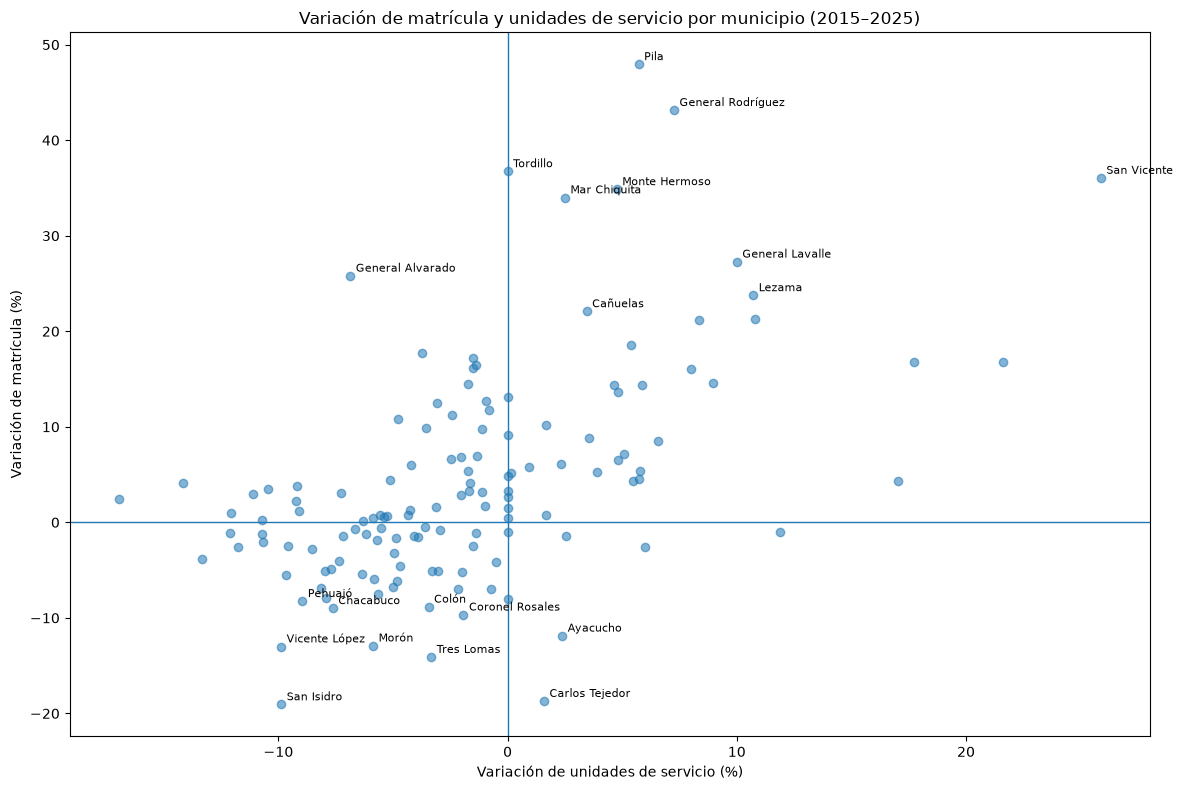

In [149]:
fig, ax = plt.subplots(figsize=(12, 8))

ax.scatter(
    comparacion_municipal["variacion_unidades_pct"],
    comparacion_municipal["variacion_matricula_pct"],
    alpha=0.55
)

# Referencias para distinguir aumentos y disminuciones
ax.axhline(0, linewidth=1)
ax.axvline(0, linewidth=1)

# Etiquetar únicamente los veinte municipios seleccionados
for _, fila in extremos_matricula.iterrows():
    ax.annotate(
        fila["municipio_nombre"],
        (
            fila["variacion_unidades_pct"],
            fila["variacion_matricula_pct"]
        ),
        fontsize=8,
        xytext=(4, 3),
        textcoords="offset points"
    )

ax.set_title(
    "Variación de matrícula y unidades de servicio por municipio (2015–2025)"
)
ax.set_xlabel("Variación de unidades de servicio (%)")
ax.set_ylabel("Variación de matrícula (%)")

plt.tight_layout()
plt.show()

¿Los municipios que registraron mayores aumentos porcentuales de unidades de servicio tendieron también a registrar mayores aumentos porcentuales de matrícula entre 2015 y 2025?

In [150]:
# Seleccionar las dos variables del análisis
datos_correlacion = comparacion_municipal[
    [
        "variacion_unidades_pct",
        "variacion_matricula_pct"
    ]
]

# Comprobar datos faltantes
print("Valores faltantes por variable:")
print(datos_correlacion.isna().sum())

# Correlación de Pearson
pearson = datos_correlacion.corr(method="pearson").iloc[0, 1]

# Correlación de Spearman
spearman = datos_correlacion.corr(method="spearman").iloc[0, 1]

print(f"\nCorrelación de Pearson:  {pearson:.3f}")
print(f"Correlación de Spearman: {spearman:.3f}")

Valores faltantes por variable:
anio
variacion_unidades_pct     0
variacion_matricula_pct    0
dtype: int64

Correlación de Pearson:  0.539
Correlación de Spearman: 0.557


In [152]:
# Extremos de variación de unidades de servicio
extremos_unidades = pd.concat([
    comparacion_municipal.nlargest(
        10, "variacion_unidades_pct"
    ),
    comparacion_municipal.nsmallest(
        10, "variacion_unidades_pct"
    )
]).drop_duplicates(subset="municipio_nombre")

print(
    extremos_unidades[
        [
            "municipio_nombre",
            "variacion_unidades_pct",
            "variacion_matricula_pct"
        ]
    ].to_string(index=False)
)

municipio_nombre  variacion_unidades_pct  variacion_matricula_pct
     San Vicente               25.882353                36.040190
         Pinamar               21.621622                16.805406
          Ezeiza               17.721519                16.736730
    Villa Gesell               17.021277                 4.282877
         Alberti               11.904762                -0.961776
Presidente Perón               10.810811                21.249018
          Lezama               10.714286                23.757195
 General Lavalle               10.000000                27.272727
         Escobar                8.955224                14.595857
General Belgrano                8.333333                21.225603
       Villarino              -16.964286                 2.446208
       Patagones              -14.166667                 4.148784
  Nueve de Julio              -13.333333                -3.806806
    San Cayetano              -12.121212                -1.110778
   Adolfo 

In [153]:
# 1. Identificamos los 10 mayores y los 10 menores cambios
# porcentuales en unidades de servicio.
extremos_unidades = pd.concat([
    comparacion_municipal.nlargest(
        10, "variacion_unidades_pct"
    ),
    comparacion_municipal.nsmallest(
        10, "variacion_unidades_pct"
    )
]).drop_duplicates(subset="municipio_nombre")

# 2. Apartamos esos municipios para el análisis de sensibilidad.
municipios_extremos = extremos_unidades["municipio_nombre"]

comparacion_sin_extremos = comparacion_municipal[
    ~comparacion_municipal["municipio_nombre"].isin(
        municipios_extremos
    )
]

# 3. Comparamos las correlaciones.
print("Municipios originales:", len(comparacion_municipal))
print("Municipios sin extremos:", len(comparacion_sin_extremos))

print("\nPearson:")
print(
    "Todos:",
    comparacion_municipal[
        ["variacion_unidades_pct", "variacion_matricula_pct"]
    ].corr(method="pearson").iloc[0, 1]
)
print(
    "Sin extremos:",
    comparacion_sin_extremos[
        ["variacion_unidades_pct", "variacion_matricula_pct"]
    ].corr(method="pearson").iloc[0, 1]
)

print("\nSpearman:")
print(
    "Todos:",
    comparacion_municipal[
        ["variacion_unidades_pct", "variacion_matricula_pct"]
    ].corr(method="spearman").iloc[0, 1]
)
print(
    "Sin extremos:",
    comparacion_sin_extremos[
        ["variacion_unidades_pct", "variacion_matricula_pct"]
    ].corr(method="spearman").iloc[0, 1]
)

Municipios originales: 135
Municipios sin extremos: 115

Pearson:
Todos: 0.5393770038821047
Sin extremos: 0.5062605395697772

Spearman:
Todos: 0.5565091939159195
Sin extremos: 0.5211780407649815


Podemos sostener que:
1. En el conjunto de los 135 municipios, las variaciones porcentuales de unidades de servicio y matrícula presentan una asociación positiva moderada.
2. La asociación se mantiene al apartar temporalmente los 20 municipios con mayores y menores variaciones porcentuales en unidades.
3. Hay municipios que se apartan del patrón general, por lo que la correlación no debe interpretarse como una regla aplicable a cada municipio.
4. El análisis no permite afirmar que el aumento de unidades provoque un aumento de matrícula, ni a la inversa.

También conviene recordar que correlacionamos variaciones porcentuales acumuladas entre 2015 y 2025, no niveles anuales ni cambios interanuales.

¿qué municipios presentan una combinación especialmente marcada de variación de unidades y matrícula?

In [154]:
# Municipios con las mayores diferencias entre ambas variaciones.
comparacion_municipal["diferencia_variaciones"] = (
    comparacion_municipal["variacion_matricula_pct"]
    - comparacion_municipal["variacion_unidades_pct"]
)

comparacion_municipal["diferencia_variaciones"].describe()

count    135.000000
mean       6.019384
std        9.769882
min      -20.305168
25%        0.195920
50%        4.983502
75%       10.378842
max       42.227281
Name: diferencia_variaciones, dtype: float64

In [155]:
# Diez municipios donde la matrícula creció más
# (o cayó menos) en relación con las unidades.
mayores_diferencias = comparacion_municipal.nlargest(
    10, "diferencia_variaciones"
)

# Diez municipios donde las unidades variaron más
# (o cayeron menos) en relación con la matrícula.
menores_diferencias = comparacion_municipal.nsmallest(
    10, "diferencia_variaciones"
)

columnas = [
    "municipio_nombre",
    "variacion_unidades_pct",
    "variacion_matricula_pct",
    "diferencia_variaciones"
]

print("MAYORES DIFERENCIAS")
print(mayores_diferencias[columnas].to_string(index=False))

print("\nMENORES DIFERENCIAS")
print(menores_diferencias[columnas].to_string(index=False))

MAYORES DIFERENCIAS
     municipio_nombre  variacion_unidades_pct  variacion_matricula_pct  diferencia_variaciones
                 Pila                5.714286                47.941567               42.227281
             Tordillo                0.000000                36.732329               36.732329
    General Rodríguez                7.258065                43.138117               35.880052
     General Alvarado               -6.862745                25.799589               32.662334
         Mar Chiquita                2.500000                33.998101               31.498101
        Monte Hermoso                4.761905                34.855681               30.093777
            Magdalena               -3.750000                17.690749               21.440749
            Villarino              -16.964286                 2.446208               19.410494
Exaltación de la Cruz               -1.492537                17.159596               18.652133
             Cañuelas         

In [156]:
municipios_a_revisar = [
    "Pila",
    "Tordillo",
    "General Rodríguez",
    "General Alvarado",
    "Villarino",
    "Carlos Tejedor",
    "Ayacucho",
    "Alberti",
    "Villa Gesell",
    "San Isidro",
]

detalle_municipios = variaciones_absolutas[
    variaciones_absolutas["municipio_nombre"].isin(
        municipios_a_revisar
    )
].copy()

print(
    detalle_municipios.sort_values(
        "municipio_nombre"
    ).to_string(index=False)
)

 municipio_nombre  matricula_2015  matricula_2025  unidades_de_servicio_2015  unidades_de_servicio_2025  cambio_matricula  cambio_unidades  contribucion_cambio_matricula_pct
          Alberti            4055            4016                         42                         47               -39                5                          -0.044665
         Ayacucho            9952            8770                         84                         86             -1182                2                          -1.353704
   Carlos Tejedor            6224            5059                         63                         64             -1165                1                          -1.334234
 General Alvarado           14101           17739                        102                         95              3638               -7                           4.166476
General Rodríguez           36404           52108                        124                        133             15704         

https://catalogo.datos.gba.gob.ar/dataset/ampliaciones-sistema-educativo/archivo/a3b0d714-b6eb-4f08-892c-1e4ed887c354?